In [2]:
import os
import ast
import math
import pickle
import re
import sys

import matplotlib
import matplotlib.pyplot as plt
matplotlib.rcParams['text.usetex'] = False
import numpy as np
import pandas as pd
from sklearn.metrics import matthews_corrcoef
from tqdm import tqdm

sys.path.insert(0, '..')
from plot_config import MODEL_COLORS, MODEL_DISPLAY_NAMES, FONT_SIZES

plt.rcParams['figure.dpi'] = 300
plt.rcParams.update(FONT_SIZES)

In [3]:
data_types = ["with_errors_5e-06i_0.004s_300bp"] # toggle here to switch between error rates and read lengths
overlap_criteria = 1

# Parse seq_len from data_type string
seq_len = int(re.search(r'(\d+)bp', data_types[0]).group(1))

if "5e-06i_0.004s" in data_types[0]:
    error_rate_title = r"0.001\% indel error rate, 0.4\% substitution error rate per base"
elif "1.25e-05i_0.01s" in data_types[0]:
    error_rate_title = r"0.0025\% indel error rate, 1\% substitution error rate per base"
elif "3.75e-05i_0.03s" in data_types[0]:
    error_rate_title = r"0.0075\% indel error rate, 3\% substitution error rate per base"

In [4]:
project_root = "/tmp/nrt204/FragmentPredictor" #"../../../.."

# Toggle: set True to load pre-computed results from disk (fast), False to run full data processing
LOAD_PROCESSED_DATA = False

all_test_accessions = open(f"{project_root}/data/processed_data/genome_partitions/test_partition_accessions.txt").read().splitlines()

# Load genome info from CSV and create dict for all test accessions
genome_info_df = pd.read_csv(f"{project_root}/data/processed_data/dataset_information/genomes_info_with_partitions.csv")
genome_info_df = genome_info_df.set_index('accession')

# Families that use translation table 4 (Mycoplasmataceae and related)
TT4_FAMILIES = ['Mycoplasmataceae']

all_genomes = {}
for acc in all_test_accessions:
    if acc in genome_info_df.index:
        row = genome_info_df.loc[acc]
        # Assign translation table based on family
        translation_table = 4 if row['family'] in TT4_FAMILIES else 11
        all_genomes[acc] = {
            'family': row['family'],
            'domain': row['domain'],
            'gc_content': row['gc_content'],
            'translation_table': translation_table
        }

# Create filtered accession lists by translation table
tt4_accessions = [acc for acc in all_test_accessions if acc in all_genomes and all_genomes[acc]['translation_table'] == 4]
tt11_accessions = [acc for acc in all_test_accessions if acc in all_genomes and all_genomes[acc]['translation_table'] == 11]

print(f"Translation Table 4 genomes: {len(tt4_accessions)}")
print(f"Translation Table 11 genomes: {len(tt11_accessions)}")

#"Reference" test accessions (1 per family)
genomes = {
    'GCF_000011125.1': {'translation_table': 11, 'gc_content': 56.3, 'domain': 'Archaea'},
    'GCF_000008665.1': {'translation_table': 11, 'gc_content': 48.6, 'domain': 'Archaea'},
    'GCF_004799605.1': {'translation_table': 11, 'gc_content': 66.3, 'domain': 'Archaea'},
    'GCF_000017165.1': {'translation_table': 11, 'gc_content': 31.3, 'domain': 'Archaea'},
    'GCF_000007345.1': {'translation_table': 11, 'gc_content': 42.7, 'domain': 'Archaea'},
    'GCF_000012545.1': {'translation_table': 11, 'gc_content': 27.6, 'domain': 'Archaea'},
    'GCF_000007365.1': {'translation_table': 11, 'gc_content': 25.3, 'domain': 'Bacteria'},
    'GCF_000009045.1': {'translation_table': 11, 'gc_content': 43.5, 'domain': 'Bacteria'},
    'GCF_025998455.1': {'translation_table': 11, 'gc_content': 38.5, 'domain': 'Bacteria'},
    'GCF_000195955.2': {'translation_table': 11, 'gc_content': 65.6, 'domain': 'Bacteria'},
    'GCF_020736045.1': {'translation_table': 11, 'gc_content': 38.2, 'domain': 'Bacteria'},
    'GCF_000012765.1': {'translation_table': 4, 'gc_content': 23.8, 'domain': 'Bacteria'},
    'GCF_028609885.1': {'translation_table': 11, 'gc_content': 61.4, 'domain': 'Bacteria'},
    'GCF_000005845.2': {'translation_table': 11, 'gc_content': 50.8, 'domain': 'Bacteria'},
    'GCF_000006765.1': {'translation_table': 11, 'gc_content': 66.6, 'domain': 'Bacteria'},
    'GCF_000013425.1': {'translation_table': 11, 'gc_content': 32.9, 'domain': 'Bacteria'}}

test_accessions = list(genomes.keys()) #List of the "reference" test accessions 

_script_name = "organisms_families_gc_content"
_cache_dir = f"{project_root}/data/processed_data/report_results/with_errors/{_script_name}"

Translation Table 4 genomes: 3
Translation Table 11 genomes: 212


In [5]:
def get_full_cds(reads_dict):
    """Merge fragmented CDS annotations, preserving per-fragment RF as sub-spans.

    Instead of labelling merged entries 'disrupted_rf', the merged entry stores
    a list of the original [start, end, rf] fragments under the key
    'disrupted_fragments'. This allows codon-level MCC to assign each sub-span
    its correct reading frame rather than skipping it.

    The merged entry format is:
        [start_of_span, end_of_span, 'disrupted_rf', [[s1,e1,rf1], [s2,e2,rf2], ...]]
    """
    for read in reads_dict.keys():
        cds_fragments_connections = reads_dict[read]['cds_fragments_connection']
        cds_coords = reads_dict[read]['cds_coords']

        indices_to_remove = []

        for cds_frag_mapping in cds_fragments_connections:
            if len(cds_frag_mapping) > 1:

                if len(cds_fragments_connections) != cds_frag_mapping[0] + 1:
                    if len(cds_frag_mapping) == 1:
                        cds_frag_mapping = [cds_index - 1 for cds_index in cds_frag_mapping]

                elif len(cds_fragments_connections) == 1 and cds_frag_mapping == [0, 2]:
                    cds_frag_mapping = [0, 1]
                elif len(cds_fragments_connections) == 1 and cds_frag_mapping == [2, 3, 4]:
                    cds_frag_mapping = [0, 1, 2]

                # Preserve original fragments with their RFs before merging
                original_fragments = [list(cds_coords[i]) for i in sorted(cds_frag_mapping)]

                start_cds_frag = cds_coords[min(cds_frag_mapping)][0]
                end_cds_frag = cds_coords[max(cds_frag_mapping)][1]

                indices_to_remove += cds_frag_mapping

                assert start_cds_frag < end_cds_frag, "Something went wrong processing indel-induced error in sequence!"
                cds_coords.append([start_cds_frag, end_cds_frag, 'disrupted_rf', original_fragments])
                reads_dict[read]['cds_coords'] = cds_coords

        for index in sorted(indices_to_remove, reverse=True):
            cds_coords.pop(index)

    return reads_dict

In [6]:
def load_in_processed_datasets(test_accession, data_type, project_root=project_root):
    #Load in testset data
    with open(f"{project_root}/data/processed_data/testset_processed/{data_type}/{test_accession}/testset_dict.pkl", "rb") as testset_dict_file:
        testset_dict = pickle.load(testset_dict_file)

    with open(f"{project_root}/data/processed_data/testset_processed/{data_type}/{test_accession}/read_names_list.pkl", "rb") as read_names_list_file:
        read_names_list = pickle.load(read_names_list_file)

    #Load on prodigal preds
    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/prodigal_preds/{data_type}/{test_accession}/model_preds_dict.pkl", "rb") as preds_prodigal_dict_file:
        preds_prodigal = pickle.load(preds_prodigal_dict_file)

    #Load in FGS predictions
    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/fgs_preds/{data_type}_complete/{test_accession}.pkl", "rb") as preds_fgs_dict_file:
        preds_fgs_complete = pickle.load(preds_fgs_dict_file)
    
    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/fgs_preds/{data_type}_illumina_5/{test_accession}.pkl", "rb") as preds_fgs_dict_file:
        preds_fgs_illumina_5 = pickle.load(preds_fgs_dict_file)

    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/fgs_preds/{data_type}_illumina_10/{test_accession}.pkl", "rb") as preds_fgs_dict_file:
        preds_fgs_illumina_10 = pickle.load(preds_fgs_dict_file)

    #Load in DeepCDS predictions (all 3 models)
    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/DeepCDS/model_without_errors/{data_type}/full_model_all_genomes_seed_42_trained_final_8M_no_dropout/{test_accession}/model_preds_dict.pkl", "rb") as model_preds_dict_file:
        preds_deep_cds_no_errors = pickle.load(model_preds_dict_file)

    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/DeepCDS/model_with_substitution_errors/{data_type}/full_model_all_genomes_seed_42_trained_final_8M_no_dropout/{test_accession}/model_preds_dict.pkl", "rb") as model_preds_dict_file:
        preds_deep_cds_substitution = pickle.load(model_preds_dict_file) 

    with open(f"{project_root}/data/processed_data/predictions/processed_predictions/DeepCDS/model_with_errors/{data_type}/full_model_all_genomes_seed_42_trained_final_8M_no_dropout/{test_accession}/model_preds_dict.pkl", "rb") as model_preds_dict_file:
        preds_deep_cds_errors = pickle.load(model_preds_dict_file)
        
    return read_names_list, get_full_cds(testset_dict), get_full_cds(preds_prodigal), \
        get_full_cds(preds_fgs_complete), get_full_cds(preds_fgs_illumina_5), get_full_cds(preds_fgs_illumina_10), \
        get_full_cds(preds_deep_cds_no_errors), \
        get_full_cds(preds_deep_cds_substitution), get_full_cds(preds_deep_cds_errors)

In [7]:
def calculate_iou(coord1, coord2):
    start1, stop1, rf1 = coord1[0], coord1[1], coord1[2]
    start2, stop2, rf2 = coord2[0], coord2[1], coord2[2]
    
    if rf1 != rf2:
        return 0.0
    
    intersection_start = max(start1, start2)
    intersection_stop = min(stop1, stop2)
    
    if intersection_start >= intersection_stop:
        return 0.0
    
    intersection_length = intersection_stop - intersection_start
    
    union_start = min(start1, start2)
    union_stop = max(stop1, stop2)
    union_length = union_stop - union_start
    
    return intersection_length / union_length if union_length > 0 else 0.0

In [8]:
def find_matching_genes(predicted_coords, actual_coords, overlap_criteria):
    """
    Find matching genes based on IoU overlap criteria.

    Args:
        predicted_coords (list): List of predicted gene coordinates (tuples).
        actual_coords (list): List of actual gene coordinates (tuples).
        overlap_criteria (float): Minimum IoU required to consider a match.
    
    Returns:
        matched_pairs: list of (pred_idx, actual_idx) pairs that match
        len(matched_paires) = tp_count: number of true positives
    """

    #Initialize
    matched_pairs = []
    used_actual = set()  #Track which actual genes have been matched
    used_predicted = set()  #Track which predicted genes have been matched
    
    #For each predicted gene, find the best matching actual gene
    for pred_idx, pred_coord in enumerate(predicted_coords):
        best_iou = 0.0
        best_actual_idx = -1
        
        for actual_idx, actual_coord in enumerate(actual_coords):
            #Skip if this actual gene is already matched
            if actual_idx in used_actual:
                continue
                
            iou = calculate_iou(pred_coord, actual_coord)
            
            #Check if this is better than current best and meets criteria
            if iou >= overlap_criteria and iou > best_iou:
                best_iou = iou
                best_actual_idx = actual_idx
        
        #If we found a valid match
        if best_actual_idx != -1:
            matched_pairs.append((pred_idx, best_actual_idx))
            used_actual.add(best_actual_idx)
            used_predicted.add(pred_idx)

    
    return matched_pairs, len(matched_pairs)


In [9]:
# Codon-level evaluation: shared functions (eval/codon_level_functions.py). Codons of annotated CDS <= 60 bp are
# MASKED (excluded from TP/FP/FN/TN for all models) and predicted CDS <= 60 bp count as non-coding predictions.
from codon_level_functions import calculate_performance_metrics_model, filter_short_predictions, short_cds_mask_spans
from codon_level_functions import matthews_corrcoef as _mcc  # used by plot_all_models_comparison


def calculate_codon_mcc(testset_dict, model_preds_dict, read_names_list, seq_len, mask_spans=None):
    """Codon-level MCC for one model; mask_spans = short_cds_mask_spans(<read CSV>) for the genome."""
    codons_per_rf = (seq_len - 3) // 3
    preds, _ = filter_short_predictions(model_preds_dict)
    m = calculate_performance_metrics_model(testset_dict, preds, read_names_list, codons_per_rf, codons_per_rf * 3,
                                            mask_spans=mask_spans)
    return {
        'codon_mcc': m['mcc'],
        'codon_tp': m['tp'], 'codon_fp': m['fp'], 'codon_fn': m['fn'], 'codon_tn': m['tn'],
        'codon_masked': m['masked'],
    }

def calculate_metrics(testset_dict, model_preds_dict, all_test_read_names, overlap_criteria):
    """
    Calculate sensitivity, precision, and F1-score for given overlap criteria.
    Overlap is based on IoU (Intersection over Union).
    
    Precision (PPV): The ratio of true positives to all predicted genes; TP / (TP + FP)
    Sensitivity (Recall): The ratio of true positives to all actual genes; TP / (TP + FN)
    F1-score: Harmonic mean of precision and sensitivity; 2 * (precision * sensitivity) / (precision + sensitivity)
    
    Args:
        testset_dict: Dictionary containing ground truth CDS coordinates
        model_preds_dict: Dictionary containing predicted CDS coordinates
        all_test_read_names: List of all read names to evaluate
        overlap_criteria: Minimum IoU threshold for considering a match (0.0< to 1.0)
    
    Returns:
        results: Dictionary containing calculated metrics
    """
    
    #Initialize
    total_tp = 0
    total_predicted_genes = 0
    total_actual_genes = 0
    
    #Iterate through each read
    for read_name in all_test_read_names:

        #Get coordinates for this read; both for test set and model predictions
        cds_coords_testset = []
        cds_coords_model = []
        
        if read_name in testset_dict:
            cds_coords_testset = testset_dict[read_name].get("cds_coords", [])
        
        if read_name in model_preds_dict:
            cds_coords_model = model_preds_dict[read_name].get("cds_coords", [])
        
        #Count genes for this read
        num_predicted = len(cds_coords_model) #predicted gene fragments
        num_actual = len(cds_coords_testset)  #actual gene fragments

        #Find matching genes based on overlap criteria
        _, tp_count = find_matching_genes(cds_coords_model, cds_coords_testset, overlap_criteria)

        #Update counts
        total_predicted_genes += num_predicted
        total_actual_genes += num_actual
        total_tp += tp_count
    
    #Calculate overall metrics
    total_fp = total_predicted_genes - total_tp
    total_fn = total_actual_genes - total_tp
    
    #Calculate precision
    precision = total_tp / total_predicted_genes if total_predicted_genes > 0 else 0.0
    
    #Calculate recall/sensitivity
    recall = total_tp / total_actual_genes if total_actual_genes > 0 else 0.0
    
    #Calculate F1-score (harmonic mean of precision and recall)
    f1_score = 2 * (precision * recall) / (precision + recall) if (precision + recall) > 0 else 0.0
    
    #Store results
    results = {
        'overlap_criteria': overlap_criteria,
        'total_predicted_genes': total_predicted_genes,
        'total_actual_genes': total_actual_genes,
        'total_true_positives': total_tp,
        'total_false_positives': total_fp,
        'total_false_negatives': total_fn,
        'precision': round(precision, 3),
        'recall': round(recall, 3),
        'f1_score': round(f1_score, 3)
    }
    
    return results

In [10]:
def get_metric_for_models(performance_metric, performance_metrics_genomes_dict):
    """ 
    Get performance metric for all models across genomes in a easy-to-plot dictionary format.

    Args:
        performance_metric (str): The performance metric to extract (e.g., 'precision', 'recall', 'f1_score').
        performance_metrics_genomes_dict (dict): A dictionary containing performance metrics for each genome and model.
    
    Returns:
        performance_metric_dict (dict): A dictionary with lists of the specified performance metric for each model and genome accession.
    """
    #Initialize
    performance_metric_dict = dict()
    performance_metric_dict["prodigal"] = []
    performance_metric_dict["fgs_complete"] = []
    performance_metric_dict["deep_cds"] = []
    performance_metric_dict["genome_accession"] = []

    #Extract metric for each genome and model
    for genome_accession in performance_metrics_genomes_dict.keys():
        performance_metric_dict["prodigal"].append(performance_metrics_genomes_dict[genome_accession]["prodigal"][performance_metric])
        performance_metric_dict["fgs_complete"].append(performance_metrics_genomes_dict[genome_accession]["fgs_complete"][performance_metric])
        performance_metric_dict["deep_cds"].append(performance_metrics_genomes_dict[genome_accession]["deep_cds"][performance_metric])
        performance_metric_dict["genome_accession"].append(genome_accession)

    # Extract data
    genome_accessions = performance_metric_dict['genome_accession']
    prodigal_scores = performance_metric_dict['prodigal']
    fgs_scores = performance_metric_dict['fgs_complete']
    deep_cds_scores = performance_metric_dict['deep_cds']

    return genome_accessions, prodigal_scores, fgs_scores, deep_cds_scores

In [11]:
def get_metric_for_models(performance_metric, performance_metrics_genomes_dict):
    """
    Get performance metric for all models across genomes in a easy-to-plot dictionary format.
    
    Args:
        performance_metric (str): The performance metric to extract (e.g., 'precision', 'recall', 'f1_score').
        performance_metrics_genomes_dict (dict): A dictionary containing performance metrics for each genome and model.
    
    Returns:
        dict: A dictionary with genome accessions and model scores
    """
    if not performance_metrics_genomes_dict:
        return {}
    
    # Get model names from the first genome entry
    first_genome = next(iter(performance_metrics_genomes_dict.values()))
    model_names = [key for key in first_genome.keys()]
    
    # Initialize result dictionary
    result_dict = {"genome_accession": []}
    for model_name in model_names:
        result_dict[model_name] = []
    
    # Extract metric for each genome and model
    for genome_accession, models_data in performance_metrics_genomes_dict.items():
        result_dict["genome_accession"].append(genome_accession)
        
        for model_name in model_names:
            if model_name in models_data and performance_metric in models_data[model_name]:
                result_dict[model_name].append(models_data[model_name][performance_metric])
            else:
                result_dict[model_name].append(None)  # Handle missing data
    
    return result_dict

In [12]:
def plot_metric_per_genome_bars(metric_data, metric_name, data_type, model_display_names=None, colors=None, genome_metadata=None):
    """
    Plot specified performance metric across different genomes and models using bar charts.
    
    Args:
        metric_data (dict): Dictionary containing genome accessions and model scores
        metric_name (str): Name of the performance metric to display on the y-axis
        model_display_names (dict, optional): Dictionary mapping model names to display names
        colors (list, optional): List of colors for the bars. If None, default colors will be used
        genome_metadata (dict, optional): Dictionary with genome metadata (translation_table, gc_content, domain)
    """
    genome_accessions = metric_data["genome_accession"]
    model_names = [key for key in metric_data.keys() if key != "genome_accession"]
    
    if not model_names:
        print("No model data found!")
        return
    
    # Create extended x-axis labels with metadata
    if genome_metadata is not None:
        x_labels = []
        for acc in genome_accessions:
            if acc in genome_metadata:
                meta = genome_metadata[acc]
                tt = meta.get('translation_table', 'N/A')
                gc = meta.get('gc_content', 'N/A')
                domain = meta.get('domain', 'N/A')[0]  # First letter (B/A)
                label = f"{acc}\n(TT:{tt}, GC:{gc}\\%, {domain})"
            else:
                label = acc
            x_labels.append(label)
    else:
        x_labels = genome_accessions
    
    # Set up display names
    if model_display_names is None:
        display_names = {name: name for name in model_names}
    else:
        display_names = model_display_names
    
    # Set up colors
    if colors is None:
        default_colors = ['cornflowerblue', 'lightgreen', 'orchid', 'coral', 'gold', 'lightgray', 'pink', 'lightcyan']
        colors = default_colors[:len(model_names)]
    
    # Create x positions for the bars
    x = np.arange(len(genome_accessions))
    n_models = len(model_names)
    width = 0.9 / n_models  # Adjust width based on number of models
    
    # Create the plot
    matplotlib.rcParams['text.usetex'] = False
    fig, ax = plt.subplots(figsize=(max(13, len(genome_accessions) * 1.5), 8))
    
    bars_list = []
    # Create bars for each model
    for i, model_name in enumerate(model_names):
        scores = metric_data[model_name]
        # Filter out None values for plotting
        valid_scores = [score if score is not None else 0 for score in scores]
        
        x_pos = x - (n_models - 1) * width / 2 + i * width
        bars = ax.bar(x_pos, valid_scores, width, 
                     label=display_names.get(model_name, model_name), 
                     alpha=0.8, color=colors[i % len(colors)])
        bars_list.append(bars)
    
    # Customize the plot
    ax.set_ylabel(metric_name.replace("_", "-"), fontsize=16)
    ax.set_title(f'{metric_name.replace("_", "-")} Across Models and Genomes in Test Set (Overall CDS-level) \n {error_rate_title}', fontsize=18, fontweight='normal')
    ax.set_xticks(x)
    ax.set_xticklabels(x_labels, rotation=30, ha='right', fontsize=11)
    ax.tick_params(axis='y', labelsize=12)
    
    # Legend: single row, positioned below x-axis labels to avoid overlap
    ax.legend(bbox_to_anchor=(0.5, -0.2), loc='upper center', ncol=len(model_names), fontsize=12)
    
    """
    # Add value labels on bars
    def add_value_labels(bars, scores):
        for bar, score in zip(bars, scores):
            if score is not None:
                height = bar.get_height()
                ax.text(bar.get_x() + bar.get_width()/2., height + 0.002,
                       f'{height:.3f}', ha='center', va='bottom', fontsize=11)
    
    for bars, model_name in zip(bars_list, model_names):
        add_value_labels(bars, metric_data[model_name])
    """
    # Set y-axis limits for better visualization
    ax.set_ylim(0, 1.05)
    
    # Tighten x-axis margins to reduce empty space on sides
    ax.set_xlim(-0.5, len(genome_accessions) - 0.5)
    
    # Add grid for better readability
    ax.grid(True, alpha=0.3, axis='y')
    
    # Adjust layout to prevent label cutoff
    plt.tight_layout()
    
    # Display the plot
    plt.show()

In [13]:
def plot_all_models_comparison(performance_metric, performance_metrics_genomes_dict, data_type, genome_metadata=None):
    """
    Convenience function to extract data and plot all models for a given metric.
    Also prints a LaTeX table with species as rows, models as columns, best value per
    row in bold, and an aggregated row at the bottom.

    Args:
        performance_metric (str): The performance metric to plot
        performance_metrics_genomes_dict (dict): Performance metrics dictionary
        data_type (str): Data type description for the plot title
        genome_metadata (dict, optional): Dictionary with genome metadata for extended x-axis labels
    """
    # Extract the data
    metric_data = get_metric_for_models(performance_metric, performance_metrics_genomes_dict)

    model_order = ["fgs_complete", "fgs_illumina_5", "fgs_illumina_10", "prodigal",
                   "deep_cds_no_errors",
                   "deep_cds_substitution", "deep_cds_errors"]
    model_display_names = MODEL_DISPLAY_NAMES
    custom_colors = [MODEL_COLORS[k] for k in model_order]

    # Plot the data
    plot_metric_per_genome_bars(metric_data, performance_metric.title(), data_type,
                               model_display_names, custom_colors, genome_metadata)

    # --- LaTeX table: species x models ---
    genome_accessions = metric_data["genome_accession"]
    model_names = [m for m in model_order if m in metric_data]
    n_cols = len(model_names)

    def _bold(val):
        return r"\textbf{" + val + "}"

    rows = []

    # Per-species rows
    for acc, scores_row in zip(genome_accessions,
                               zip(*[metric_data[m] for m in model_names])):
        if acc in genome_info_df.index:
            species = genome_info_df.loc[acc, 'species']
            name = species if pd.notna(species) and species != '' else acc
        else:
            name = acc
        parts = name.split(' ', 1)
        sp_label = (r"\textit{" + f"{parts[0][0]}. {parts[1]}" + r"}"
                    if len(parts) == 2 else name)

        values = [s if s is not None else 0.0 for s in scores_row]
        max_val = max(values)
        cells = [_bold(f"{v:.3f}") if v == max_val else f"{v:.3f}" for v in values]
        rows.append(sp_label + " & " + " & ".join(cells) + r" \\")

    # Aggregated row (recompute from raw TP/FP/FN)
    agg_values = []
    for model in model_names:
        genome_values = [v[model] for v in performance_metrics_genomes_dict.values() if model in v]
        if performance_metric == 'codon_mcc':
            agg_tp = sum(v.get('codon_tp', 0) for v in genome_values)
            agg_fp = sum(v.get('codon_fp', 0) for v in genome_values)
            agg_fn = sum(v.get('codon_fn', 0) for v in genome_values)
            agg_tn = sum(v.get('codon_tn', 0) for v in genome_values)
            agg_values.append(_mcc(agg_tp, agg_fp, agg_fn, agg_tn))
        else:
            total_tp = sum(v.get('total_true_positives', 0) for v in genome_values)
            total_fp = sum(v.get('total_false_positives', 0) for v in genome_values)
            total_fn = sum(v.get('total_false_negatives', 0) for v in genome_values)
            precision = total_tp / (total_tp + total_fp) if (total_tp + total_fp) > 0 else 0
            recall    = total_tp / (total_tp + total_fn) if (total_tp + total_fn) > 0 else 0
            f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            agg_values.append({'f1_score': f1, 'precision': precision, 'recall': recall}
                              .get(performance_metric, f1))

    max_agg = max(agg_values)
    agg_cells = [_bold(f"{v:.3f}") if v == max_agg else f"{v:.3f}" for v in agg_values]

    # Build LaTeX with grouped headers and resizebox
    metric_label = performance_metric.replace("_", " ").title()

    fgs_group     = ["fgs_complete", "fgs_illumina_5", "fgs_illumina_10"]
    deepcds_group = ["deep_cds_no_errors", "deep_cds_substitution", "deep_cds_errors"]
    short_names = {
        "fgs_complete":             "Complete",
        "fgs_illumina_5":           r"0.5\% err",
        "fgs_illumina_10":          r"1.0\% err",
        "prodigal":                 "MetaProdigal",
        "deep_cds_no_errors":       "Full",
        "deep_cds_substitution":    "S (Full)",
        "deep_cds_errors":          "S+I (Full)",
    }

    # Column positions (1-indexed, col 1 = Species)
    fgs_cols     = [i + 2 for i, m in enumerate(model_names) if m in fgs_group]
    deepcds_cols = [i + 2 for i, m in enumerate(model_names) if m in deepcds_group]

    # First header row: multicolumn group labels
    header1_parts = [""]  # empty Species cell
    i = 0
    while i < len(model_names):
        m = model_names[i]
        if m in fgs_group:
            n = sum(1 for x in model_names if x in fgs_group)
            header1_parts.append(r"\multicolumn{" + str(n) + r"}{c}{FGS}")
            i += n
        elif m == "prodigal":
            header1_parts.append("")
            i += 1
        elif m in deepcds_group:
            n = sum(1 for x in model_names if x in deepcds_group)
            header1_parts.append(r"\multicolumn{" + str(n) + r"}{c}{DeepCDS}")
            i += n
        else:
            header1_parts.append("")
            i += 1

    cmidrule = ""
    if fgs_cols:
        cmidrule += r"\cmidrule(lr){" + str(fgs_cols[0]) + "-" + str(fgs_cols[-1]) + "}"
    if deepcds_cols:
        cmidrule += r" \cmidrule(lr){" + str(deepcds_cols[0]) + "-" + str(deepcds_cols[-1]) + "}"

    short_headers = [short_names.get(m, MODEL_DISPLAY_NAMES.get(m, m)) for m in model_names]

    latex = []
    latex.append(r"\begin{table}[ht]")
    latex.append(r"\centering")
    latex.append(r"\resizebox{\textwidth}{!}{%")
    latex.append(r"\begin{tabular}{l" + "c" * n_cols + "}")
    latex.append(r"\toprule")
    latex.append(" & ".join(header1_parts) + r" \\")
    latex.append(cmidrule)
    latex.append(r"Species & " + " & ".join(short_headers) + r" \\")
    latex.append(r"\midrule")
    latex.extend(rows)
    latex.append(r"\midrule")
    latex.append(r"\textbf{Aggregated} & " + " & ".join(agg_cells) + r" \\")
    latex.append(r"\bottomrule")
    latex.append(r"\end{tabular}%")
    latex.append(r"}")
    latex.append(r"\caption{" + metric_label + r" per reference organism (one per family). "
                 r"Bold indicates best-performing model per row.}")
    latex.append(r"\label{tab:per_genome_" + performance_metric + r"}")
    latex.append(r"\end{table}")

    print("\n".join(latex))

In [14]:
def find_wrong_predictions(testset_dict, model_preds_dict, all_test_read_names, overlap_criteria):
    """
    Find reads with wrong predictions (false positives or false negatives).
    
    Args:
        testset_dict: Dictionary containing ground truth CDS coordinates
        model_preds_dict: Dictionary containing predicted CDS coordinates
        all_test_read_names: List of all read names to evaluate
        overlap_criteria: Minimum IoU threshold for considering a match
    
    Returns:
        wrong_predictions: Dictionary with details about wrong predictions per read
    """
    wrong_predictions = {
        'reads_with_fp': [],  # Reads with false positives
        'reads_with_fn': [],  # Reads with false negatives
        'all_errors': [],     # All reads with any error
        'detailed_errors': {} # Detailed info per read
    }
    
    for read_name in all_test_read_names:
        # Get coordinates for this read
        cds_coords_testset = []
        cds_coords_model = []
        
        if read_name in testset_dict:
            cds_coords_testset = testset_dict[read_name].get("cds_coords", [])
        
        if read_name in model_preds_dict:
            cds_coords_model = model_preds_dict[read_name].get("cds_coords", [])
        
        num_predicted = len(cds_coords_model)
        num_actual = len(cds_coords_testset)
        
        # Find matching genes
        matched_pairs, tp_count = find_matching_genes(cds_coords_model, cds_coords_testset, overlap_criteria)
        
        # Calculate FP and FN for this read
        fp_count = num_predicted - tp_count
        fn_count = num_actual - tp_count
        
        has_error = fp_count > 0 or fn_count > 0
        
        if has_error:
            # Get indices of matched predictions and actuals
            matched_pred_indices = {pair[0] for pair in matched_pairs}
            matched_actual_indices = {pair[1] for pair in matched_pairs}
            
            # Find unmatched predictions (false positives)
            fp_coords = [cds_coords_model[i] for i in range(num_predicted) if i not in matched_pred_indices]
            
            # Find unmatched actuals (false negatives)
            fn_coords = [cds_coords_testset[i] for i in range(num_actual) if i not in matched_actual_indices]
            
            wrong_predictions['detailed_errors'][read_name] = {
                'predicted_coords': cds_coords_model,
                'actual_coords': cds_coords_testset,
                'matched_pairs': matched_pairs,
                'false_positive_coords': fp_coords,
                'false_negative_coords': fn_coords,
                'fp_count': fp_count,
                'fn_count': fn_count
            }
            
            wrong_predictions['all_errors'].append(read_name)
            
            if fp_count > 0:
                wrong_predictions['reads_with_fp'].append(read_name)
            if fn_count > 0:
                wrong_predictions['reads_with_fn'].append(read_name)
    
    # Summary statistics
    wrong_predictions['summary'] = {
        'total_reads': len(all_test_read_names),
        'reads_with_errors': len(wrong_predictions['all_errors']),
        'reads_with_fp': len(wrong_predictions['reads_with_fp']),
        'reads_with_fn': len(wrong_predictions['reads_with_fn']),
        'error_rate': len(wrong_predictions['all_errors']) / len(all_test_read_names) if all_test_read_names else 0
    }
    
    return wrong_predictions

# Main

# Plot performance on overall reference test organisms

Saved performance_metrics_genomes_dict to /tmp/nrt204/FragmentPredictor/data/processed_data/report_results/with_errors/organisms_families_gc_content_masked/with_errors_5e-06i_0.004s_300bp


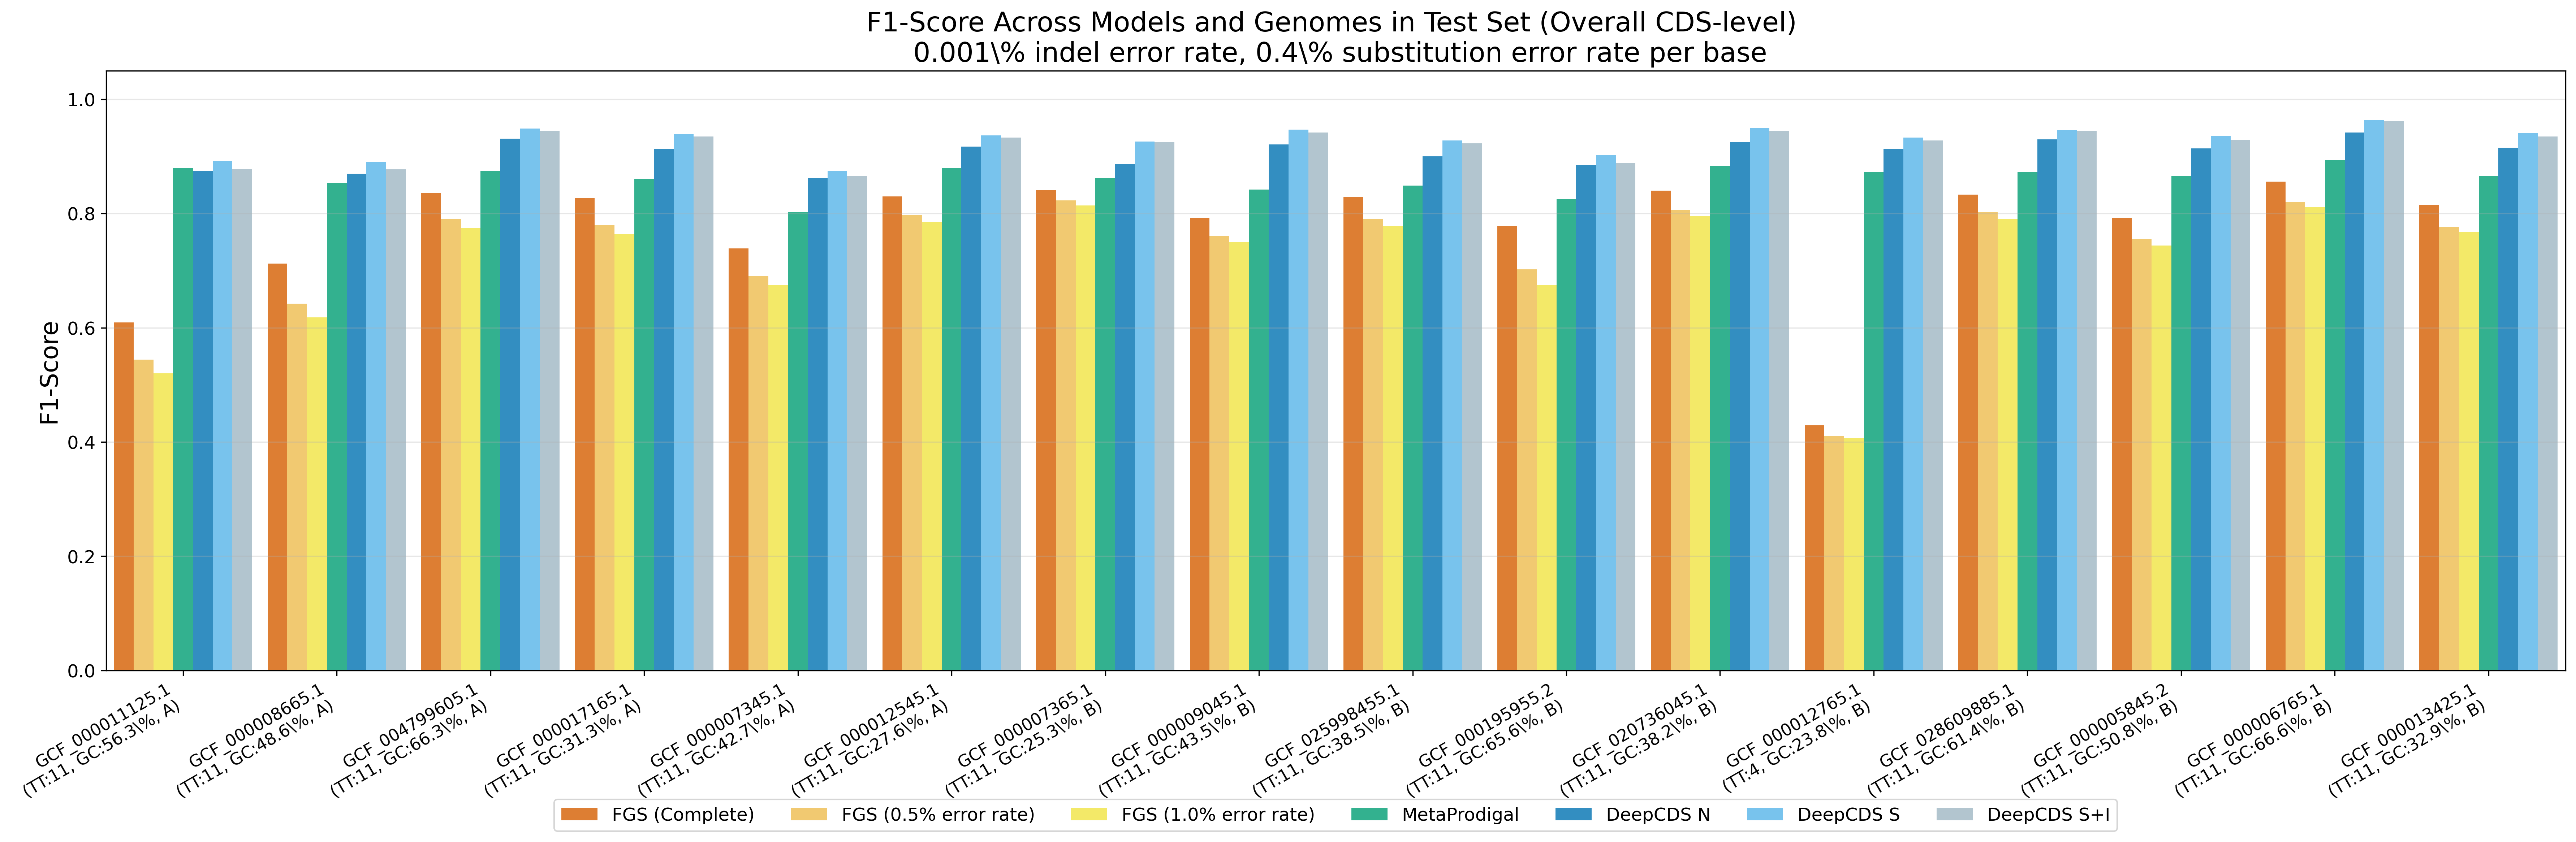

\begin{table}[ht]
\centering
\resizebox{\textwidth}{!}{%
\begin{tabular}{lccccccc}
\toprule
 & \multicolumn{3}{c}{FGS} &  & \multicolumn{3}{c}{DeepCDS} \\
\cmidrule(lr){2-4} \cmidrule(lr){6-8}
Species & Complete & 0.5\% err & 1.0\% err & MetaProdigal & Full & S (Full) & S+I (Full) \\
\midrule
\textit{A. pernix} & 0.609 & 0.544 & 0.520 & 0.879 & 0.875 & \textbf{0.892} & 0.878 \\
\textit{A. fulgidus} & 0.712 & 0.642 & 0.618 & 0.854 & 0.870 & \textbf{0.890} & 0.877 \\
\textit{H. salinarum} & 0.836 & 0.791 & 0.774 & 0.874 & 0.931 & \textbf{0.949} & 0.944 \\
\textit{M. vannielii} & 0.827 & 0.779 & 0.764 & 0.860 & 0.913 & \textbf{0.939} & 0.935 \\
\textit{M. acetivorans} & 0.739 & 0.691 & 0.675 & 0.802 & 0.862 & \textbf{0.875} & 0.865 \\
\textit{M. stadtmanae} & 0.830 & 0.797 & 0.785 & 0.879 & 0.917 & \textbf{0.937} & 0.933 \\
\textit{B. aphidicola} & 0.841 & 0.823 & 0.814 & 0.862 & 0.887 & \textbf{0.926} & 0.925 \\
\textit{B. subtilis} & 0.792 & 0.761 & 0.750 & 0.842 & 0.921 & \textbf{0.947

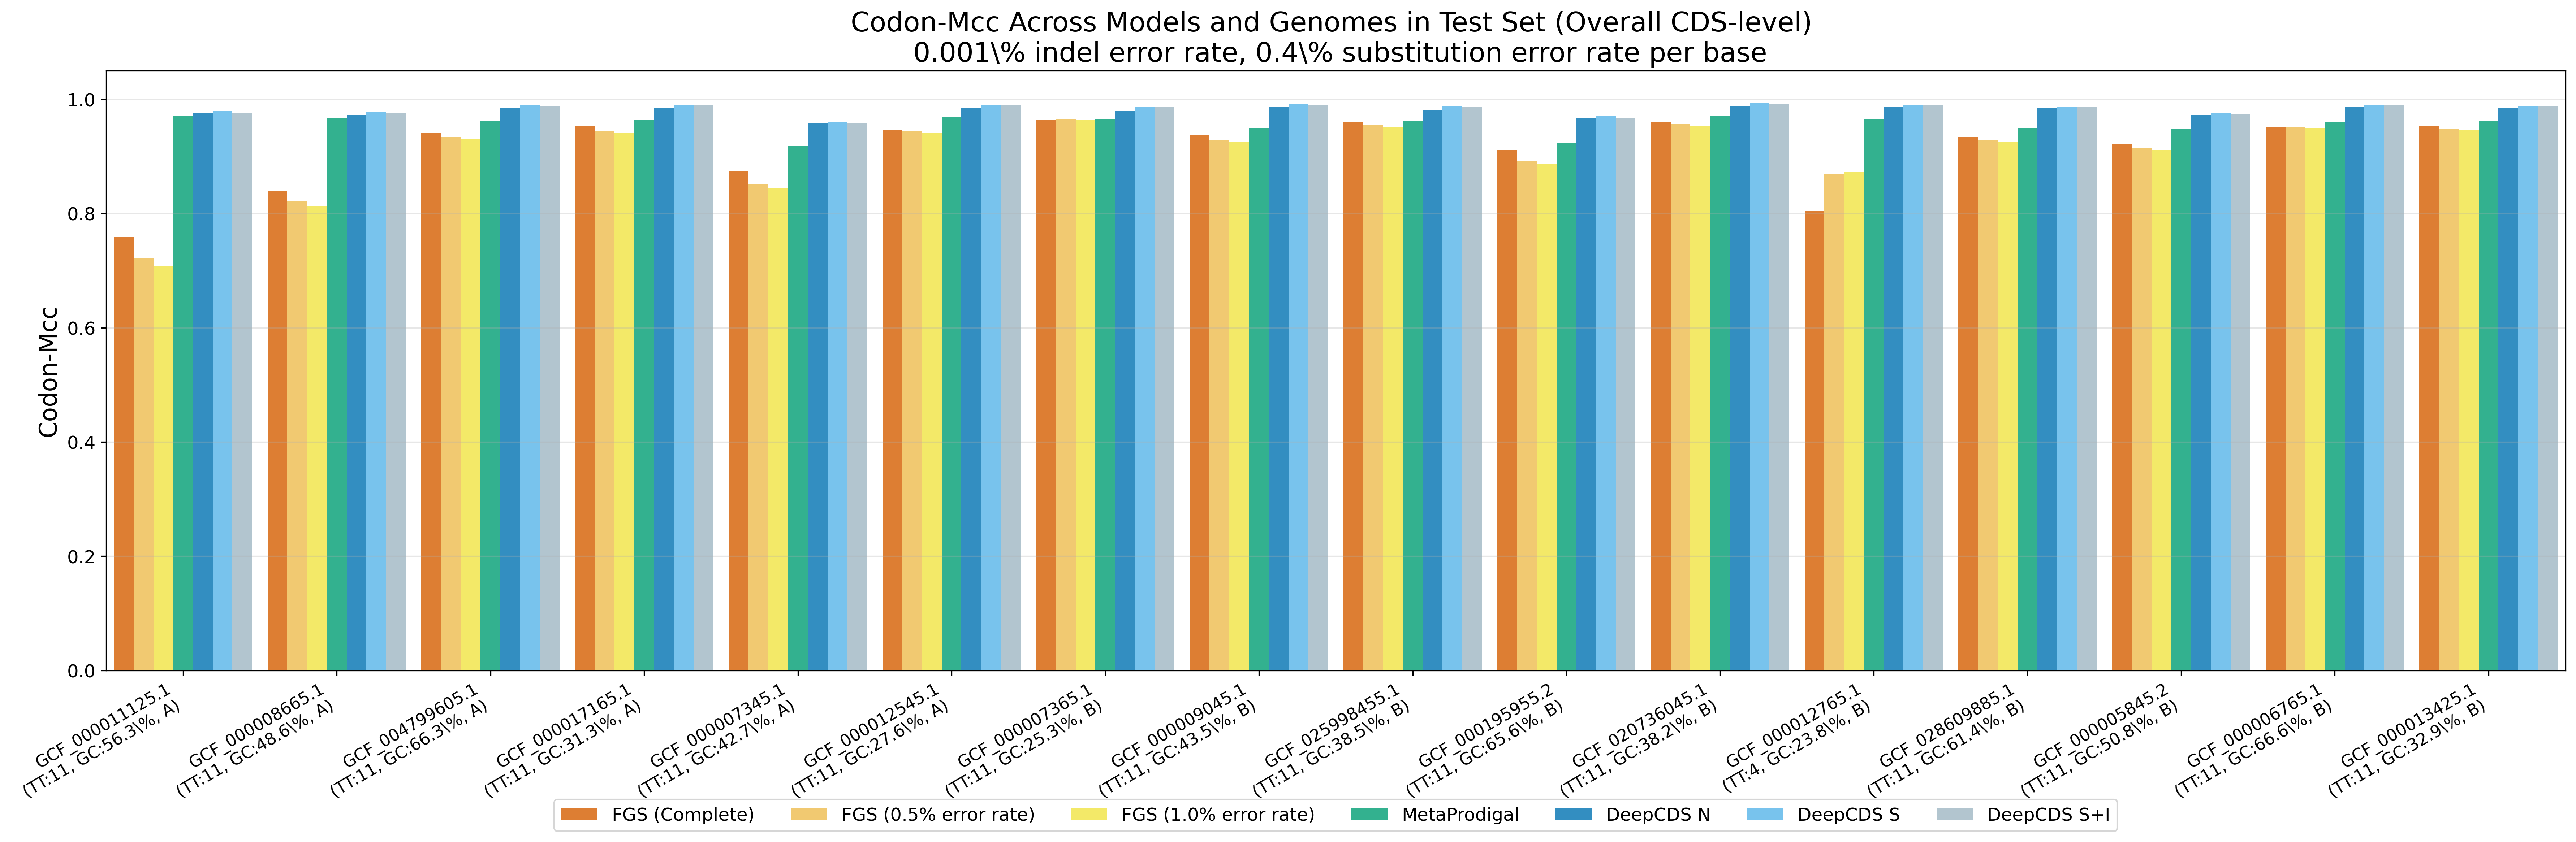

\begin{table}[ht]
\centering
\resizebox{\textwidth}{!}{%
\begin{tabular}{lccccccc}
\toprule
 & \multicolumn{3}{c}{FGS} &  & \multicolumn{3}{c}{DeepCDS} \\
\cmidrule(lr){2-4} \cmidrule(lr){6-8}
Species & Complete & 0.5\% err & 1.0\% err & MetaProdigal & Full & S (Full) & S+I (Full) \\
\midrule
\textit{A. pernix} & 0.759 & 0.722 & 0.707 & 0.971 & 0.976 & \textbf{0.979} & 0.976 \\
\textit{A. fulgidus} & 0.839 & 0.821 & 0.813 & 0.968 & 0.973 & \textbf{0.978} & 0.976 \\
\textit{H. salinarum} & 0.942 & 0.934 & 0.931 & 0.962 & 0.985 & \textbf{0.989} & 0.989 \\
\textit{M. vannielii} & 0.954 & 0.945 & 0.941 & 0.964 & 0.984 & \textbf{0.991} & 0.989 \\
\textit{M. acetivorans} & 0.874 & 0.852 & 0.845 & 0.918 & 0.958 & \textbf{0.960} & 0.958 \\
\textit{M. stadtmanae} & 0.947 & 0.945 & 0.942 & 0.969 & 0.985 & 0.990 & \textbf{0.991} \\
\textit{B. aphidicola} & 0.964 & 0.965 & 0.964 & 0.966 & 0.979 & 0.987 & \textbf{0.987} \\
\textit{B. subtilis} & 0.936 & 0.929 & 0.926 & 0.949 & 0.986 & \textbf{0.991

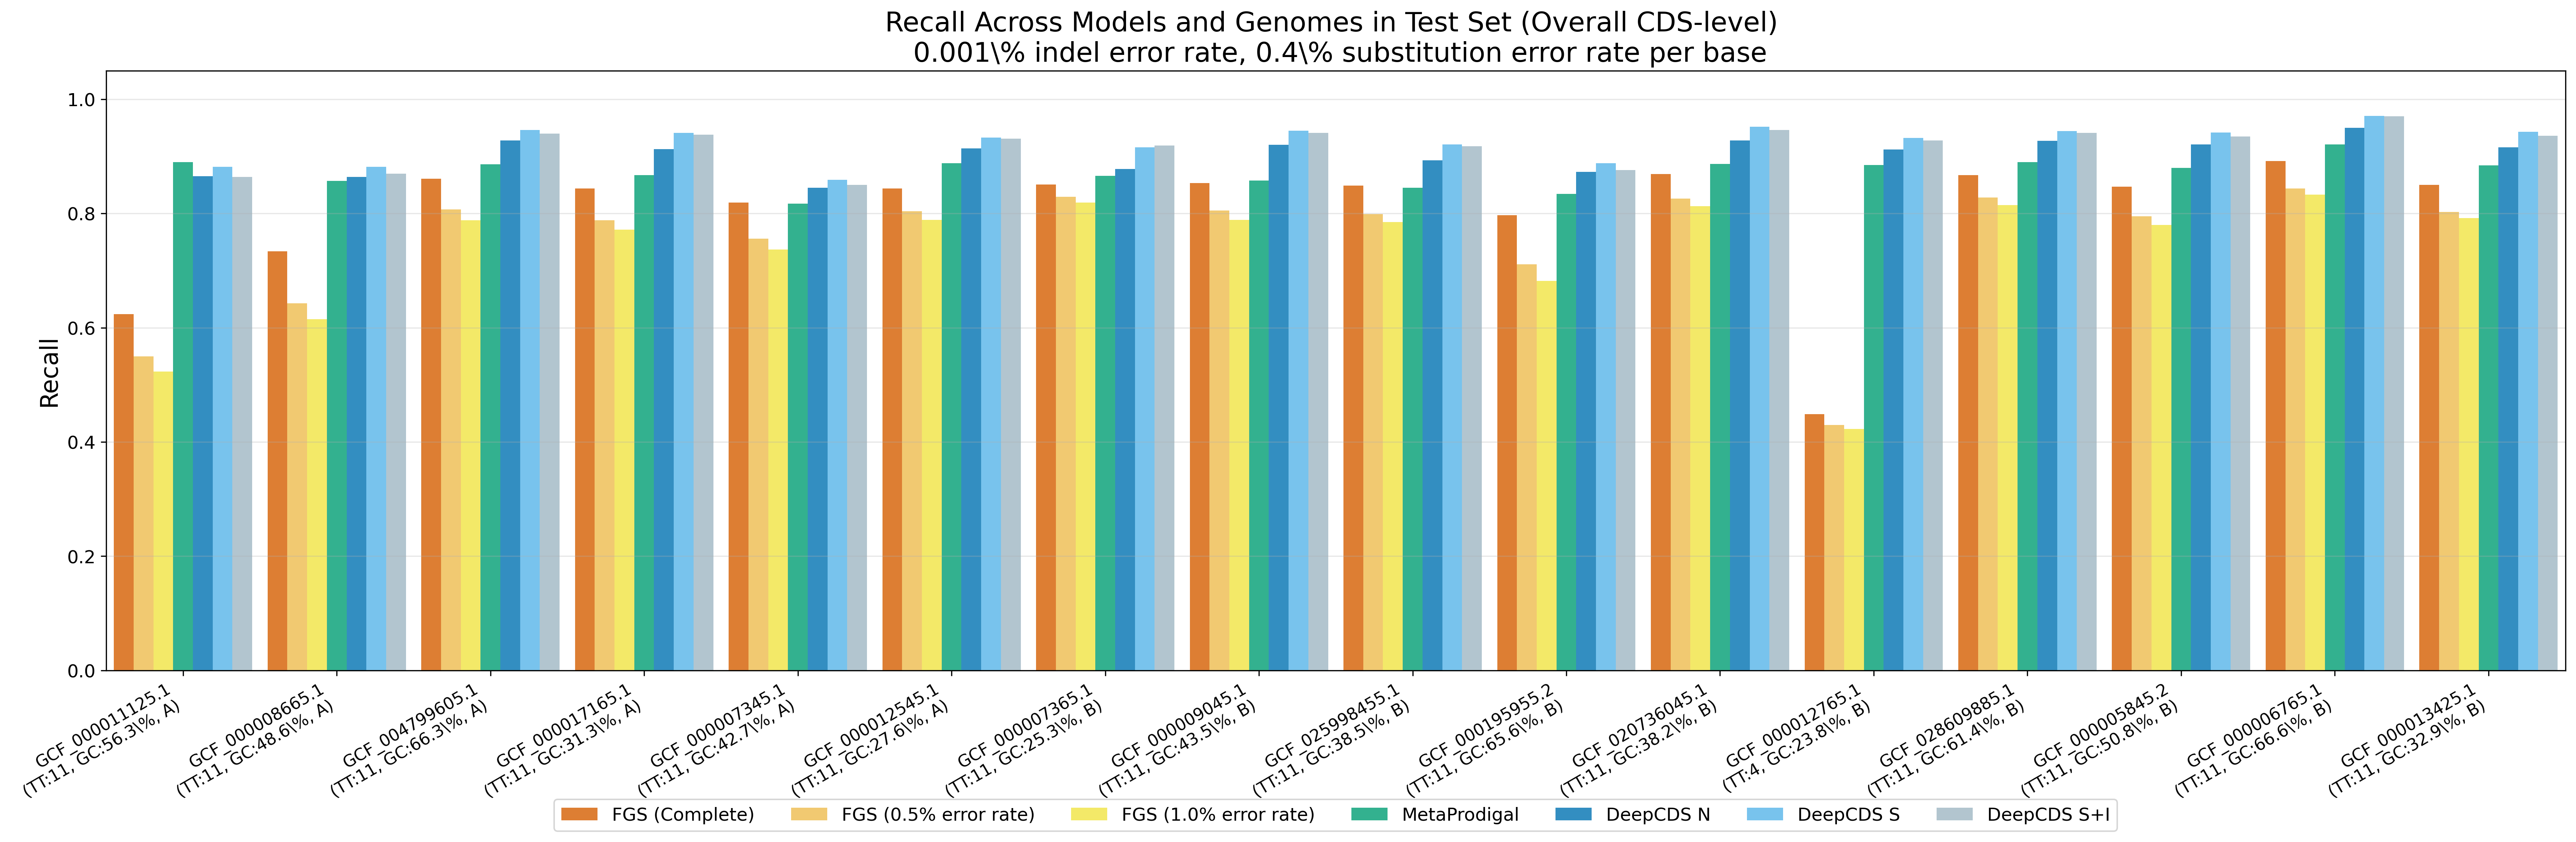

\begin{table}[ht]
\centering
\resizebox{\textwidth}{!}{%
\begin{tabular}{lccccccc}
\toprule
 & \multicolumn{3}{c}{FGS} &  & \multicolumn{3}{c}{DeepCDS} \\
\cmidrule(lr){2-4} \cmidrule(lr){6-8}
Species & Complete & 0.5\% err & 1.0\% err & MetaProdigal & Full & S (Full) & S+I (Full) \\
\midrule
\textit{A. pernix} & 0.624 & 0.550 & 0.523 & \textbf{0.890} & 0.865 & 0.882 & 0.864 \\
\textit{A. fulgidus} & 0.734 & 0.643 & 0.615 & 0.857 & 0.864 & \textbf{0.882} & 0.870 \\
\textit{H. salinarum} & 0.861 & 0.807 & 0.788 & 0.886 & 0.928 & \textbf{0.946} & 0.940 \\
\textit{M. vannielii} & 0.844 & 0.788 & 0.772 & 0.867 & 0.913 & \textbf{0.941} & 0.938 \\
\textit{M. acetivorans} & 0.819 & 0.756 & 0.737 & 0.817 & 0.845 & \textbf{0.859} & 0.850 \\
\textit{M. stadtmanae} & 0.844 & 0.804 & 0.789 & 0.888 & 0.914 & \textbf{0.933} & 0.931 \\
\textit{B. aphidicola} & 0.851 & 0.829 & 0.819 & 0.866 & 0.878 & 0.916 & \textbf{0.919} \\
\textit{B. subtilis} & 0.853 & 0.805 & 0.789 & 0.858 & 0.920 & \textbf{0.945

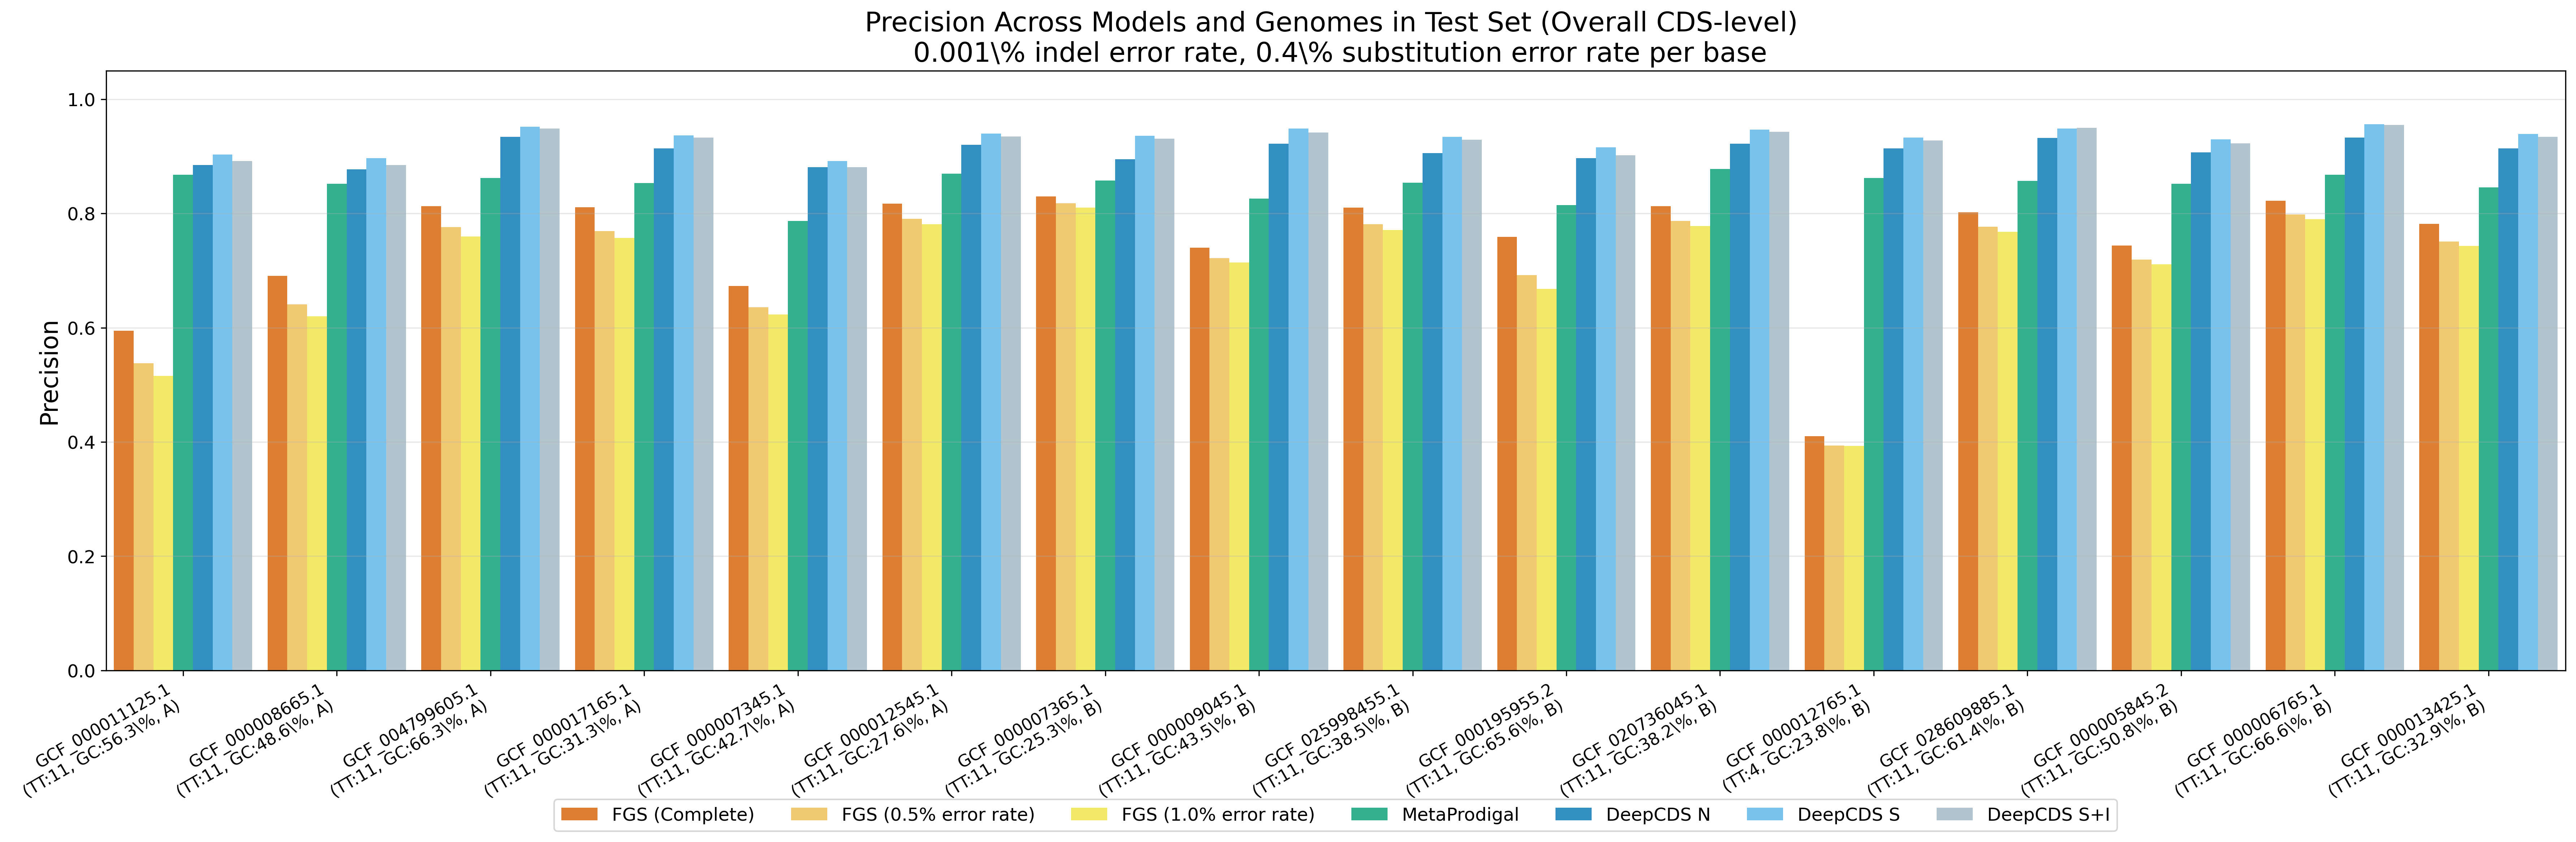

\begin{table}[ht]
\centering
\resizebox{\textwidth}{!}{%
\begin{tabular}{lccccccc}
\toprule
 & \multicolumn{3}{c}{FGS} &  & \multicolumn{3}{c}{DeepCDS} \\
\cmidrule(lr){2-4} \cmidrule(lr){6-8}
Species & Complete & 0.5\% err & 1.0\% err & MetaProdigal & Full & S (Full) & S+I (Full) \\
\midrule
\textit{A. pernix} & 0.595 & 0.538 & 0.516 & 0.868 & 0.885 & \textbf{0.903} & 0.892 \\
\textit{A. fulgidus} & 0.691 & 0.641 & 0.620 & 0.852 & 0.877 & \textbf{0.897} & 0.885 \\
\textit{H. salinarum} & 0.813 & 0.776 & 0.760 & 0.862 & 0.934 & \textbf{0.952} & 0.949 \\
\textit{M. vannielii} & 0.811 & 0.769 & 0.757 & 0.853 & 0.914 & \textbf{0.937} & 0.933 \\
\textit{M. acetivorans} & 0.673 & 0.636 & 0.623 & 0.787 & 0.881 & \textbf{0.892} & 0.881 \\
\textit{M. stadtmanae} & 0.817 & 0.791 & 0.781 & 0.870 & 0.920 & \textbf{0.940} & 0.935 \\
\textit{B. aphidicola} & 0.830 & 0.818 & 0.810 & 0.858 & 0.895 & \textbf{0.936} & 0.931 \\
\textit{B. subtilis} & 0.740 & 0.722 & 0.714 & 0.826 & 0.922 & \textbf{0.949

In [15]:
for data_type in data_types:
    # Codon-level metrics use masked short annotated CDS -> separate cache (the earlier cache is left untouched)
    _dt_cache_dir = os.path.join(f"{_cache_dir}_masked", data_type)

    if not LOAD_PROCESSED_DATA:
        performance_metrics_genomes_dict = {}

        for test_accession in test_accessions:
            read_names_list, testset_dict, prodigal_dict, \
            preds_fgs_complete_dict, preds_fgs_illumina_5_dict, preds_fgs_illumina_10_dict, \
            preds_no_errors, \
            preds_deep_cds_substitution, preds_deep_cds_errors = load_in_processed_datasets(test_accession, data_type)
            mask_spans = short_cds_mask_spans(
                f"{project_root}/data/processed_data/reads_processed/test/{data_type}/csv/{test_accession}.csv.gz")

            performance_metrics_genomes_dict[test_accession] = {
                "fgs_complete": {
                    **calculate_metrics(testset_dict, preds_fgs_complete_dict, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_fgs_complete_dict, read_names_list, seq_len, mask_spans)
                },
                "fgs_illumina_5": {
                    **calculate_metrics(testset_dict, preds_fgs_illumina_5_dict, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_fgs_illumina_5_dict, read_names_list, seq_len, mask_spans)
                },
                "fgs_illumina_10": {
                    **calculate_metrics(testset_dict, preds_fgs_illumina_10_dict, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_fgs_illumina_10_dict, read_names_list, seq_len, mask_spans)
                },
                "prodigal": {
                    **calculate_metrics(testset_dict, prodigal_dict, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, prodigal_dict, read_names_list, seq_len, mask_spans)
                },
                "deep_cds_no_errors": {
                    **calculate_metrics(testset_dict, preds_no_errors, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_no_errors, read_names_list, seq_len, mask_spans)
                },
                "deep_cds_substitution": {
                    **calculate_metrics(testset_dict, preds_deep_cds_substitution, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_deep_cds_substitution, read_names_list, seq_len, mask_spans)
                },
                "deep_cds_errors": {
                    **calculate_metrics(testset_dict, preds_deep_cds_errors, read_names_list, overlap_criteria),
                    **calculate_codon_mcc(testset_dict, preds_deep_cds_errors, read_names_list, seq_len, mask_spans)
                },
            }

        os.makedirs(_dt_cache_dir, exist_ok=True)
        with open(os.path.join(_dt_cache_dir, 'performance_metrics_genomes_dict.pkl'), 'wb') as f:
            pickle.dump(performance_metrics_genomes_dict, f)
        print(f'Saved performance_metrics_genomes_dict to {_dt_cache_dir}')

    else:
        print(f'Loading performance_metrics_genomes_dict from {_dt_cache_dir}')
        with open(os.path.join(_dt_cache_dir, 'performance_metrics_genomes_dict.pkl'), 'rb') as f:
            performance_metrics_genomes_dict = pickle.load(f)
            
    plot_all_models_comparison('f1_score', performance_metrics_genomes_dict, data_type, genomes)
    plot_all_models_comparison('codon_mcc', performance_metrics_genomes_dict, data_type, genomes)
    plot_all_models_comparison('recall', performance_metrics_genomes_dict, data_type, genomes)
    plot_all_models_comparison('precision', performance_metrics_genomes_dict, data_type, genomes)

# Plot performance as a function of GC-content

In [16]:
def plot_metric_by_gc_content_boxplot(performance_metrics_dict, genome_metadata, metric_name, data_type,
                                       gc_bins=None, model_display_names=None, colors=None):
    """
    Plot boxplot of performance metric grouped by GC-content ranges.
    
    Args:
        performance_metrics_dict (dict): Dictionary with genome accessions as keys and model metrics as values
        genome_metadata (dict): Dictionary with genome metadata including gc_content
        metric_name (str): Name of the metric to plot (e.g., 'f1_score', 'precision', 'recall')
        data_type (str): Data type description for the plot title
        gc_bins (list, optional): List of bin edges for GC-content. Default: [0, 40, 50, 60, 100]
        model_display_names (dict, optional): Dictionary mapping model names to display names
        colors (list, optional): List of colors for each model
    """
    if gc_bins is None:
        gc_bins = [0, 40, 50, 60, 100]
    
    # Get model names from the first genome entry
    first_genome = next(iter(performance_metrics_dict.values()))
    model_names = list(first_genome.keys())
    
    # Set up display names
    if model_display_names is None:
        display_names = {name: name for name in model_names}
    else:
        display_names = model_display_names
    
    # Set up colors
    if colors is None:
        colors = ['cornflowerblue', 'gold', 'orchid', 'forestgreen', 'purple']
    
    # Create bin labels
    bin_labels = []
    for i in range(len(gc_bins) - 1):
        if gc_bins[i] == 0:
            bin_labels.append(rf"$<${gc_bins[i+1]}\%")
        elif gc_bins[i+1] == 100:
            bin_labels.append(rf"$>${gc_bins[i]}\%")
        else:
            bin_labels.append(rf"{gc_bins[i]}--{gc_bins[i+1]}\%")
    
    # Organize data by GC bin and model
    data_by_bin_and_model = {label: {model: [] for model in model_names} for label in bin_labels}
    
    for acc, metrics in performance_metrics_dict.items():
        if acc not in genome_metadata:
            continue
        
        gc = genome_metadata[acc]['gc_content']
        
        # Find the appropriate bin
        bin_label = None
        for i in range(len(gc_bins) - 1):
            if gc_bins[i] <= gc < gc_bins[i + 1]:
                bin_label = bin_labels[i]
                break
        
        if bin_label is None:
            continue
        
        # Add metric values for each model
        for model in model_names:
            if model in metrics and metric_name in metrics[model]:
                data_by_bin_and_model[bin_label][model].append(metrics[model][metric_name])
    
    # Prepare data for boxplot
    n_models = len(model_names)
    n_bins = len(bin_labels)
    
    matplotlib.rcParams['text.usetex'] = False
    fig, ax = plt.subplots(figsize=(max(12, n_bins * 2), 7))
    
    # Position parameters
    width = 0.8 / n_models
    positions_base = np.arange(n_bins)
    
    # Create boxplots for each model
    for i, model in enumerate(model_names):
        positions = positions_base + (i - (n_models - 1) / 2) * width
        data = [data_by_bin_and_model[label][model] for label in bin_labels]
        
        bp = ax.boxplot(data, positions=positions, widths=width * 0.8,
                       patch_artist=True, manage_ticks=False)
        
        # Style the boxplot
        for patch in bp['boxes']:
            patch.set_facecolor(colors[i % len(colors)])
            patch.set_alpha(0.7)
        for median in bp['medians']:
            median.set_color('black')
    
    # Customize the plot
    ax.set_xlabel('GC-content Range')
    ax.set_ylabel(metric_name.replace("_", " ").title())
    #ax.set_title(f'{metric_name.replace("_", " ").title()} by GC-content Range\n{error_rate_title}', fontsize=14)
    ax.set_xticks(positions_base)
    ax.set_xticklabels(bin_labels)
    
    # Add legend
    legend_patches = [plt.Rectangle((0, 0), 1, 1, facecolor=colors[i % len(colors)], alpha=0.7) 
                     for i in range(n_models)]
    ax.legend(legend_patches, [display_names.get(m, m) for m in model_names],
             bbox_to_anchor=(0.5, -0.08), loc='upper center', ncol=min(5, n_models),
             fontsize = 11)
    
    # Add grid
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0.0, 1.05)
    
    # Add count annotations above each bin
    for i, label in enumerate(bin_labels):
        count = len(data_by_bin_and_model[label][model_names[0]])
        ax.text(i, 1.02, f'n={count}', ha='center', va='bottom', fontsize=10)
    
    plt.tight_layout()
    # plt.savefig(f"boxplot_GC_content_{metric_name}_{data_type}.png", dpi=400)
    # plt.savefig(f"boxplot_GC_content_{metric_name}_{data_type}.svg", dpi=400)
    plt.show()

In [17]:
if not LOAD_PROCESSED_DATA:
    for data_type in data_types:
    
        # Calculate performance metrics for ALL test accessions
        all_performance_metrics_dict = {}
    
        for test_accession in tqdm(all_test_accessions, desc=f"Processing {data_type}"):
            try:
                read_names_list, testset_dict, prodigal_dict, \
                preds_fgs_complete_dict, preds_fgs_illumina_5_dict, preds_fgs_illumina_10_dict, \
                preds_no_errors, \
                preds_deep_cds_substitution, preds_deep_cds_errors = load_in_processed_datasets(test_accession, data_type)
            
                all_performance_metrics_dict[test_accession] = {
                    "fgs_complete": calculate_metrics(testset_dict, preds_fgs_complete_dict, read_names_list, overlap_criteria),
                    "fgs_illumina_5": calculate_metrics(testset_dict, preds_fgs_illumina_5_dict, read_names_list, overlap_criteria),
                    "fgs_illumina_10": calculate_metrics(testset_dict, preds_fgs_illumina_10_dict, read_names_list, overlap_criteria),
                    "prodigal": calculate_metrics(testset_dict, prodigal_dict, read_names_list, overlap_criteria),
                    "deep_cds_no_errors": calculate_metrics(testset_dict, preds_no_errors, read_names_list, overlap_criteria),
                    "deep_cds_substitution": calculate_metrics(testset_dict, preds_deep_cds_substitution, read_names_list, overlap_criteria),
                    "deep_cds_errors": calculate_metrics(testset_dict, preds_deep_cds_errors, read_names_list, overlap_criteria)
                }
            except Exception as e:
                print(f"Error processing {test_accession}: {e}")
                continue
    
else:

    for data_type in data_types:
        _dt_cache_dir = os.path.join(_cache_dir, data_type)
        print(f"Loading pre-computed results from:\n  {_dt_cache_dir}")
        with open(os.path.join(_dt_cache_dir, "all_performance_metrics_dict.pkl"), "rb") as f:
            all_performance_metrics_dict = pickle.load(f)
        print("Done.")

        
# Define display names and colors (matching data dict order)
model_display_names = MODEL_DISPLAY_NAMES
custom_colors = [MODEL_COLORS[k] for k in [
    "fgs_complete", "fgs_illumina_5", "fgs_illumina_10", "prodigal",
    "deep_cds_no_errors", "deep_cds_substitution", "deep_cds_errors"]]

Processing with_errors_5e-06i_0.004s_300bp:   2%|▏         | 4/215 [00:04<03:24,  1.03it/s]

Processing with_errors_5e-06i_0.004s_300bp: 100%|██████████| 215/215 [03:34<00:00,  1.00it/s]


In [18]:
if not LOAD_PROCESSED_DATA:
    for data_type in data_types:
        _dt_cache_dir = os.path.join(_cache_dir, data_type)
        os.makedirs(_dt_cache_dir, exist_ok=True)
        with open(os.path.join(_dt_cache_dir, "all_performance_metrics_dict.pkl"), "wb") as f:
            pickle.dump(all_performance_metrics_dict, f)
        print(f"Results saved to {_dt_cache_dir}")

Results saved to /tmp/nrt204/FragmentPredictor/data/processed_data/report_results/with_errors/organisms_families_gc_content/with_errors_5e-06i_0.004s_300bp


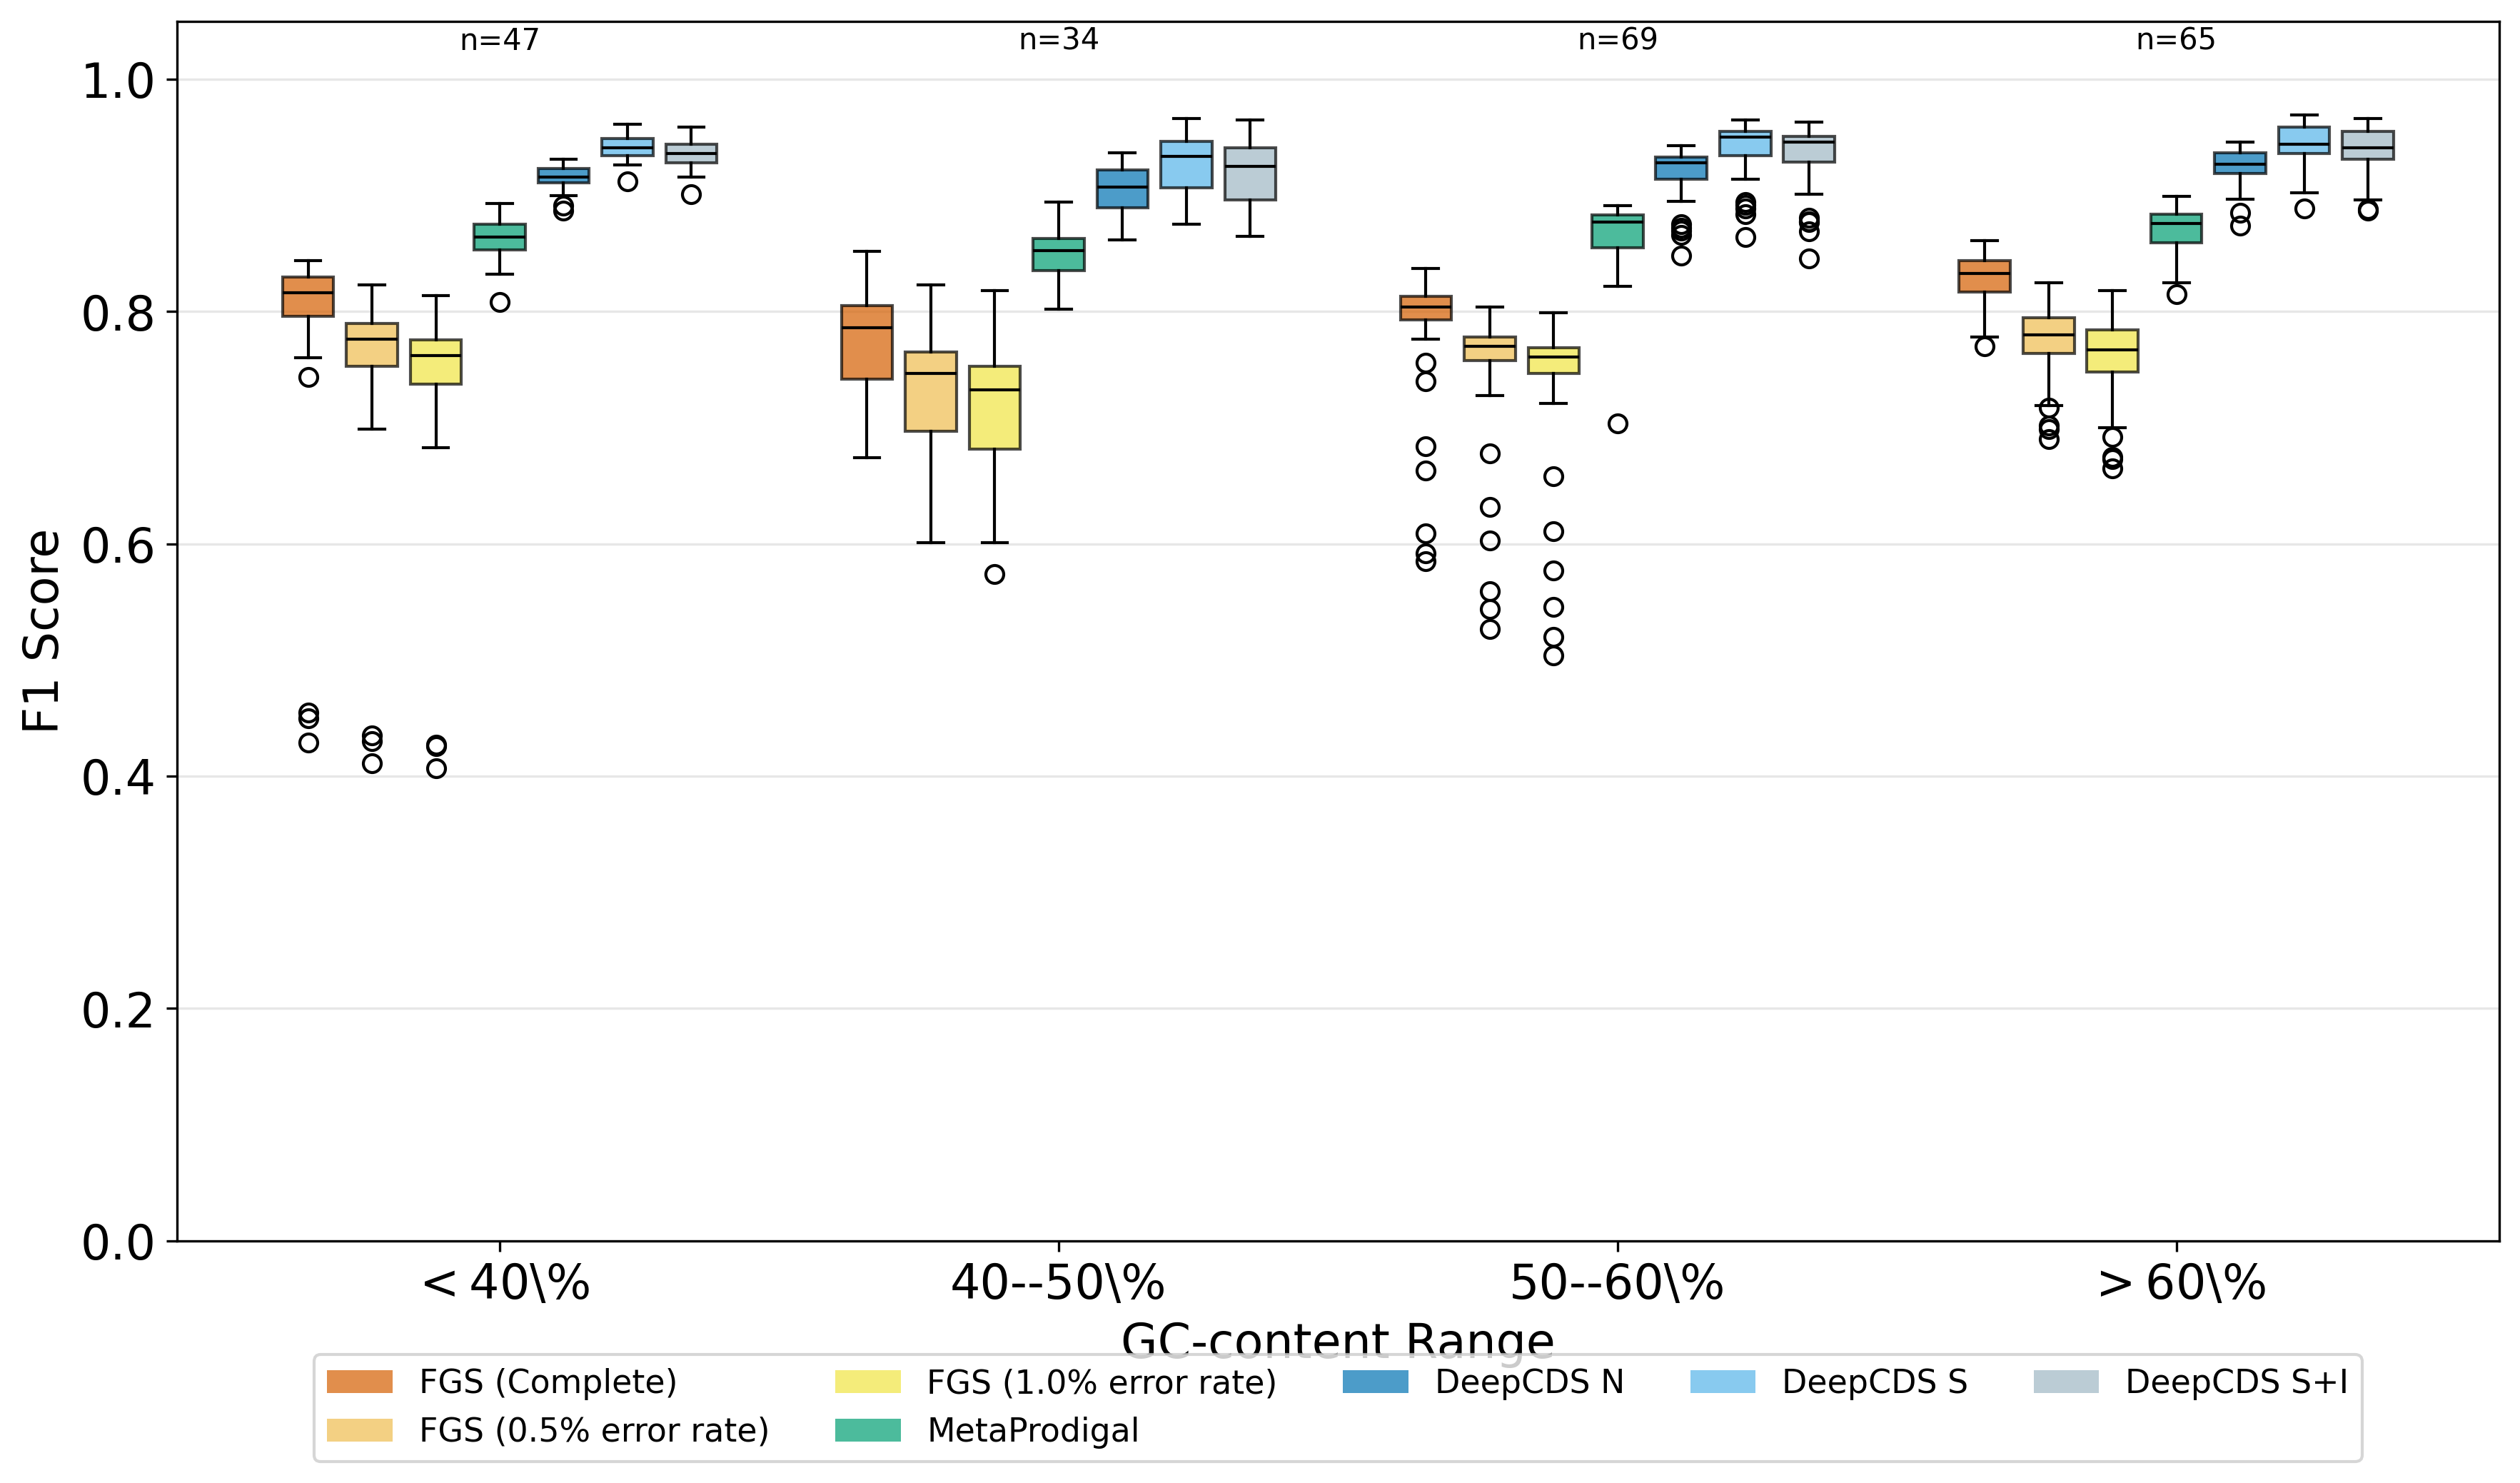

In [19]:
# Plot boxplots by GC-content
plot_metric_by_gc_content_boxplot(all_performance_metrics_dict, all_genomes, 'f1_score', data_type,
                                  model_display_names=model_display_names, colors=custom_colors)

# Plot performance as a function of GC-content as scatterplot(aggregated to GC-content category, not genome-level)

In [20]:
def plot_metric_by_gc_content_bars(performance_metrics_dict, genome_metadata, metric_name, data_type,
                                    gc_bins=None, model_display_names=None, colors=None):
    """
    Plot barplot of aggregated performance metric by GC-content ranges.
    Aggregates all predictions within each GC bin to compute a single metric.
    
    Args:
        performance_metrics_dict (dict): Dictionary with genome accessions as keys and model metrics as values
        genome_metadata (dict): Dictionary with genome metadata including gc_content
        metric_name (str): Name of the metric to plot (e.g., 'f1_score', 'precision', 'recall')
        data_type (str): Data type description for the plot title
        gc_bins (list, optional): List of bin edges for GC-content. Default: [0, 40, 50, 60, 100]
        model_display_names (dict, optional): Dictionary mapping model names to display names
        colors (list, optional): List of colors for each model
    """
    if gc_bins is None:
        gc_bins = [0, 40, 50, 60, 100]
    
    # Get model names from the first genome entry
    first_genome = next(iter(performance_metrics_dict.values()))
    model_names = list(first_genome.keys())
    
    # Set up display names
    if model_display_names is None:
        display_names = {name: name for name in model_names}
    else:
        display_names = model_display_names
    
    # Set up colors
    if colors is None:
        colors = ['gold', 'cornflowerblue', 'orchid', 'forestgreen', 'purple']
    
    # Create bin labels
    bin_labels = []
    for i in range(len(gc_bins) - 1):
        if gc_bins[i] == 0:
            bin_labels.append(rf"$<${gc_bins[i+1]}\%")
        elif gc_bins[i+1] == 100:
            bin_labels.append(rf"$>${gc_bins[i]}\%")
        else:
            bin_labels.append(rf"{gc_bins[i]}--{gc_bins[i+1]}\%")
    
    # Aggregate raw counts by GC bin and model
    aggregated_counts = {label: {model: {'tp': 0, 'fp': 0, 'fn': 0, 'count': 0} 
                                  for model in model_names} 
                         for label in bin_labels}
    
    for acc, metrics in performance_metrics_dict.items():
        if acc not in genome_metadata:
            continue
        
        gc = genome_metadata[acc]['gc_content']
        
        # Find the appropriate bin
        bin_label = None
        for i in range(len(gc_bins) - 1):
            if gc_bins[i] <= gc < gc_bins[i + 1]:
                bin_label = bin_labels[i]
                break
        
        if bin_label is None:
            continue
        
        # Aggregate counts for each model
        for model in model_names:
            if model in metrics:
                aggregated_counts[bin_label][model]['tp'] += metrics[model].get('total_true_positives', 0)
                aggregated_counts[bin_label][model]['fp'] += metrics[model].get('total_false_positives', 0)
                aggregated_counts[bin_label][model]['fn'] += metrics[model].get('total_false_negatives', 0)
                aggregated_counts[bin_label][model]['count'] += 1
    
    # Calculate aggregated metrics for each bin and model
    aggregated_metrics = {model: [] for model in model_names}
    genome_counts = []
    
    for i, label in enumerate(bin_labels):
        genome_counts.append(aggregated_counts[label][model_names[0]]['count'])
        
        for model in model_names:
            counts = aggregated_counts[label][model]
            tp, fp, fn = counts['tp'], counts['fp'], counts['fn']
            
            # Calculate metrics from aggregated counts
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            
            if metric_name == 'f1_score':
                aggregated_metrics[model].append(f1)
            elif metric_name == 'precision':
                aggregated_metrics[model].append(precision)
            elif metric_name == 'recall':
                aggregated_metrics[model].append(recall)
    
    # Create the barplot
    matplotlib.rcParams['text.usetex'] = False
    fig, ax = plt.subplots(figsize=(12, 7))
    
    n_models = len(model_names)
    n_bins = len(bin_labels)
    x = np.arange(n_bins)
    width = 0.8 / n_models
    
    # Create bars for each model
    for i, model in enumerate(model_names):
        x_pos = x - (n_models - 1) * width / 2 + i * width
        bars = ax.bar(x_pos, aggregated_metrics[model], width,
                     label=display_names.get(model, model),
                     color=colors[i % len(colors)], alpha=0.8)
        
        # Add value labels on bars
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height + 0.005,
                   f'{height:.3f}', ha='center', va='bottom', fontsize=10)
    
    # Customize the plot
    ax.set_xlabel('GC-content Range', fontsize=12)
    ax.set_ylabel(metric_name.replace("_", " ").title(), fontsize=12)
    ax.set_title(f'Aggregated {metric_name.replace("_", " ").title()} by GC-content Range\n{error_rate_title}', fontsize=14)
    ax.set_xticks(x)
    ax.set_xticklabels(bin_labels)
    
    # Add genome count annotations
    for i, count in enumerate(genome_counts):
        ax.text(i, ax.get_ylim()[1] * 0.99, f'n={count}', ha='center', va='top', fontsize=10)
    
    # Add legend
    ax.legend(bbox_to_anchor=(0.5, -0.12), loc='upper center', ncol=min(5, n_models))
    
    # Add grid
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(0.0, 1.05)
    
    plt.tight_layout()
    plt.show()

In [21]:
def plot_metric_per_family_bars(performance_metrics_dict, genome_metadata, metric_name, data_type,
                                 model_display_names=None, colors=None, min_genomes=1):
    """
    Plot barplot of aggregated performance metric per family, split into two rows.
    Row 1: Archaeal families. Row 2: Bacterial families.
    Error bars show the span (min to max) of per-genome performance within each family.

    Args:
        performance_metrics_dict (dict): Dictionary with genome accessions as keys and model metrics as values
        genome_metadata (dict): Dictionary with genome metadata including family
        metric_name (str): Name of the metric to plot (e.g., 'f1_score', 'precision', 'recall')
        data_type (str): Data type description for the plot title
        model_display_names (dict, optional): Dictionary mapping model names to display names
        colors (list, optional): List of colors for each model
        min_genomes (int): Minimum number of genomes required to include a family. Default: 1
    """
    first_genome = next(iter(performance_metrics_dict.values()))
    model_names = list(first_genome.keys())

    if model_display_names is None:
        display_names = {name: name for name in model_names}
    else:
        display_names = model_display_names

    if colors is None:
        colors = ['gold', 'cornflowerblue', 'orchid', 'forestgreen', 'purple']

    # Get all unique families and track their domain
    families = set()
    family_domain = {}
    for acc in performance_metrics_dict.keys():
        if acc in genome_metadata:
            family = genome_metadata[acc]['family']
            families.add(family)
            family_domain[family] = genome_metadata[acc]['domain']

    # Aggregate raw counts, per-genome metrics, and GC content
    aggregated_counts = {family: {model: {'tp': 0, 'fp': 0, 'fn': 0, 'count': 0}
                                   for model in model_names}
                         for family in families}
    per_genome_metrics = {family: {model: [] for model in model_names}
                          for family in families}
    family_gc_values = {family: [] for family in families}  # collect GC per genome per family

    def _compute_metric(tp, fp, fn, metric):
        precision = tp / (tp + fp) if (tp + fp) > 0 else 0
        recall    = tp / (tp + fn) if (tp + fn) > 0 else 0
        f1        = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
        return {'f1_score': f1, 'precision': precision, 'recall': recall}.get(metric, f1)

    for acc, metrics in performance_metrics_dict.items():
        if acc not in genome_metadata:
            continue
        family = genome_metadata[acc]['family']
        # Collect GC content if available
        gc = genome_metadata[acc].get('gc_content')
        if gc is not None:
            family_gc_values[family].append(gc)
        for model in model_names:
            if model in metrics:
                tp = metrics[model].get('total_true_positives', 0)
                fp = metrics[model].get('total_false_positives', 0)
                fn = metrics[model].get('total_false_negatives', 0)
                aggregated_counts[family][model]['tp'] += tp
                aggregated_counts[family][model]['fp'] += fp
                aggregated_counts[family][model]['fn'] += fn
                aggregated_counts[family][model]['count'] += 1
                per_genome_metrics[family][model].append(_compute_metric(tp, fp, fn, metric_name))

    valid_families = [f for f in families
                      if aggregated_counts[f][model_names[0]]['count'] >= min_genomes]

    def _sort_families(family_list):
        """Sort families by name, natural/numerical order."""
        return sorted(family_list, key=lambda f: [int(c) if c.isdigit() else c.lower()
                                                for c in re.split(r'(\d+)', f)])

    # Split valid families into Archaea and Bacteria, sort each independently
    archaeal_families  = _sort_families([f for f in valid_families
                                         if family_domain.get(f, '').lower() == 'archaea'])
    bacterial_families = _sort_families([f for f in valid_families
                                         if family_domain.get(f, '').lower() == 'bacteria'])

    def _build_plot_data(family_list):
        """Build aggregated values, error bars, counts, GC ranges and labels for a list of families."""
        agg      = {model: [] for model in model_names}
        err_low  = {model: [] for model in model_names}
        err_high = {model: [] for model in model_names}
        counts, labels = [], []

        for family in family_list:
            counts.append(aggregated_counts[family][model_names[0]]['count'])
            # Build x-axis label with count and GC range
            gc_vals = family_gc_values[family]
            family_display = f"{family}*" if family == 'Mycoplasmataceae' else family
            if gc_vals:
                gc_min, gc_max = min(gc_vals), max(gc_vals)
                label = f"{family_display}\n(n={counts[-1]}, GC: [{gc_min:.1f}, {gc_max:.1f}])"
            else:
                label = f"{family_display}\n(n={counts[-1]})"
            labels.append(label)

            for model in model_names:
                c = aggregated_counts[family][model]
                agg_val = _compute_metric(c['tp'], c['fp'], c['fn'], metric_name)
                agg[model].append(agg_val)
                genome_vals = per_genome_metrics[family][model]
                if len(genome_vals) > 1:
                    err_low[model].append(agg_val - min(genome_vals))
                    err_high[model].append(max(genome_vals) - agg_val)
                else:
                    err_low[model].append(0)
                    err_high[model].append(0)

        return agg, err_low, err_high, counts, labels

    n_models = len(model_names)
    width = 0.8 / n_models
    ylabel = metric_name.replace("_", " ").title()

    matplotlib.rcParams['text.usetex'] = False
    fig, axes = plt.subplots(2, 1, figsize=(18, 14))
    subplot_data = [
        (axes[0], archaeal_families,  'Archaea'),
        (axes[1], bacterial_families, 'Bacteria'),
    ]

    for ax, family_list, domain_label in subplot_data:
        agg, err_low, err_high, counts, labels = _build_plot_data(family_list)
        n = len(family_list)
        x = np.arange(n)

        for i, model in enumerate(model_names):
            x_pos = x - (n_models - 1) * width / 2 + i * width
            ax.bar(x_pos, agg[model], width,
                   label=display_names.get(model, model),
                   color=colors[i % len(colors)], alpha=0.8,
                   yerr=[err_low[model], err_high[model]], capsize=2,
                   error_kw=dict(elinewidth=0.8, ecolor='black', alpha=0.7))

        ax.set_title(domain_label, fontweight='bold', loc='left')
        ax.set_ylabel(ylabel)
        ax.set_xticks(x)
        ax.set_xticklabels(labels, rotation=20, ha='right')
        ax.margins(x=0.02)
        ax.grid(True, alpha=0.3, axis='y')
        ax.set_ylim(0.3, 1.01)

    handles, lbls = axes[0].get_legend_handles_labels()
    fig.legend(handles, lbls, bbox_to_anchor=(0.5, 0), loc='upper center',
               ncol=min(4, n_models))
    #fig.text(0.01, -0.01, '* Uses an alternative translation table',
    #     fontsize=9, fontstyle='italic', va='top')
    
    plt.tight_layout()
    plt.savefig(f'{project_root}/illustrations/results/{metric_name}_per_family_{data_type}.png', dpi=500, bbox_inches='tight')
    plt.show()

    all_sorted = archaeal_families + bacterial_families
    return all_sorted, {model: [v for fam_list in [archaeal_families, bacterial_families]
                                for v in _build_plot_data(fam_list)[0][model]]
                        for model in model_names}

In [22]:
# Reorder the metrics dict to control bar order
def reorder_metrics(metrics_dict, order):
    """Reorder the model keys in performance metrics dict."""
    reordered = {}
    for acc, models in metrics_dict.items():
        reordered[acc] = {model: models[model] for model in order if model in models}
    return reordered

model_order = ["fgs_complete", "fgs_illumina_5", "fgs_illumina_10", "prodigal",
                   "deep_cds_no_errors",
                   "deep_cds_substitution", "deep_cds_errors"]

model_display_names_ordered = {k: MODEL_DISPLAY_NAMES[k] for k in model_order}
custom_colors_ordered = [MODEL_COLORS[k] for k in model_order]

all_performance_metrics_ordered = reorder_metrics(all_performance_metrics_dict, model_order)

## Per-genome scatterplot: GC-content vs. F1 score

In [23]:
from scipy.stats import spearmanr
from matplotlib.lines import Line2D

def plot_gc_vs_metric_scatter(performance_metrics_dict, genome_metadata, metric_name, data_type,
                               model_order=None, model_display_names=None, colors=None,
                               max_cols=4, latex_groups=None):
    """
    Scatterplot of GC-content vs. per-genome performance metric, one panel per model.
    Reports Spearman correlation in each panel.

    Args:
        performance_metrics_dict (dict): {accession: {model: {metric: value, ...}}}
        genome_metadata (dict): {accession: {gc_content: float, domain: str, ...}}
        metric_name (str): metric key, e.g. 'f1_score'
        data_type (str): label for the figure title / save filename
        model_order (list, optional): order of models to plot
        model_display_names (dict, optional): {model_key: display_name}
        colors (list, optional): list of bar colors per model
        max_cols (int): maximum number of panels per row (default 4)
        latex_groups (list, optional): list of (group_name, [model_keys]) tuples for LaTeX
            table output. Use group_name=None for ungrouped models (e.g. MetaProdigal).
            When provided, prints a LaTeX table with rows=domains, columns=models, values=rho.
            Example: [('FGS', ['fgs_complete', ...]), (None, ['prodigal']), ('DeepCDS', [...])]
    """
    if model_order is None:
        model_order = list(next(iter(performance_metrics_dict.values())).keys())
    if model_display_names is None:
        model_display_names = {m: m for m in model_order}
    if colors is None:
        colors = ['#D55E00', '#009E73', '#CC79A7', '#0072B2']

    # Build aligned arrays
    accessions = [acc for acc in performance_metrics_dict
                  if acc in genome_metadata and genome_metadata[acc].get('gc_content') is not None]

    gc_arr  = np.array([genome_metadata[acc]['gc_content'] for acc in accessions])
    domains = np.array([genome_metadata[acc].get('domain', 'Unknown') for acc in accessions])

    domain_colors = {'Bacteria': '#0072B2', 'Archaea': '#D55E00'}
    domain_labels = sorted(set(domains))

    n_models = len(model_order)
    n_cols = min(n_models, max_cols)
    n_rows = math.ceil(n_models / n_cols)

    matplotlib.rcParams['text.usetex'] = False
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.5, n_rows * 4.2),
                             sharey=True, constrained_layout=True)
    axes_flat = np.array(axes).flatten()

    for idx, (model, color) in enumerate(zip(model_order, colors)):
        ax = axes_flat[idx]
        f1_arr = np.array([
            performance_metrics_dict[acc][model].get(metric_name, np.nan)
            for acc in accessions
        ])
        valid = ~np.isnan(f1_arr)
        gc_v, f1_v, dom_v = gc_arr[valid], f1_arr[valid], domains[valid]

        # Points coloured by domain
        for domain in domain_labels:
            mask = dom_v == domain
            ax.scatter(gc_v[mask], f1_v[mask],
                       c=domain_colors.get(domain, 'grey'),
                       s=10, alpha=0.8, linewidths=0, label=domain)

        # Linear regression line
        m_reg, b_reg = np.polyfit(gc_v, f1_v, 1)
        x_line = np.linspace(gc_v.min(), gc_v.max(), 200)
        ax.plot(x_line, m_reg * x_line + b_reg, color='black', lw=1.2, zorder=5)

        # Spearman correlation per domain — bottom right corner
        annotation_lines = []
        for domain in domain_labels:
            mask = dom_v == domain
            if mask.sum() >= 3:
                rho_d, p_d = spearmanr(gc_v[mask], f1_v[mask])
                p_txt = r'$<$0.001' if p_d < 0.001 else f'= {p_d:.3f}'
                annotation_lines.append((rf'$\rho$ = {rho_d:.2f}, $p$ {p_txt}', domain_colors.get(domain, 'grey')))

        for line_idx, (text, col) in enumerate(reversed(annotation_lines)):
            ax.annotate(
                text,
                xy=(0.97, 0.05 + line_idx * 0.09), xycoords='axes fraction',
                fontsize=8, va='bottom', ha='right', color=col
            )

        ax.set_title(model_display_names.get(model, model), fontsize=14)
        ax.set_xticks(range(20, 75, 10))
        ax.tick_params(axis='x', labelsize=11)

    # Hide any unused axes
    for idx in range(n_models, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Y-axis label on leftmost column
    for row in range(n_rows):
        axes_flat[row * n_cols].set_ylabel(metric_name.replace('_', ' ').title(), fontsize=14)

    fig.supxlabel('GC content', fontsize=14)

    # Shared domain legend — centred at the bottom
    legend_handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=domain_colors.get(d, 'grey'),
               markersize=7, label=d)
        for d in domain_labels
    ]
    fig.legend(handles=legend_handles,
               loc='lower center', bbox_to_anchor=(0.5, -0.04),
               ncol=len(domain_labels)+1,
               fontsize=10, title_fontsize=10, frameon=True)

    #plt.savefig(f'gc_vs_{metric_name}_scatter_{data_type}.png', dpi=500, bbox_inches='tight')
    #plt.show()
    plt.close()

    # Print plain-text correlation table
    print(f'Spearman correlation: GC content vs. {metric_name.replace("_", " ").title()}')
    print('=' * 66)
    print(f'{"Model":<26} {"Domain":<12} {"rho":>6} {"p-value":>12}')
    print('-' * 66)
    for model in model_order:
        f1_arr = np.array([
            performance_metrics_dict[acc][model].get(metric_name, np.nan)
            for acc in accessions
        ])
        valid = ~np.isnan(f1_arr)
        gc_v_all, f1_v_all, dom_v_all = gc_arr[valid], f1_arr[valid], domains[valid]
        for domain in domain_labels:
            mask = dom_v_all == domain
            if mask.sum() < 3:
                continue
            rho, p_rho = spearmanr(gc_v_all[mask], f1_v_all[mask])
            p_str = f'{p_rho:.3e}' if p_rho < 0.001 else f'{p_rho:.4f}'
            print(f'{model_display_names.get(model, model):<26} {domain:<12} {rho:>6.3f} {p_str:>12}')

    # Print LaTeX table (rows = domains, columns = models, values = Spearman rho)
    if latex_groups is not None:
        # Precompute rho for every model/domain pair
        rho_data = {}
        for model in model_order:
            f1_arr = np.array([
                performance_metrics_dict[acc][model].get(metric_name, np.nan)
                for acc in accessions
            ])
            valid = ~np.isnan(f1_arr)
            gc_v_all, f1_v_all, dom_v_all = gc_arr[valid], f1_arr[valid], domains[valid]
            rho_data[model] = {}
            for domain in domain_labels:
                mask = dom_v_all == domain
                if mask.sum() >= 3:
                    rho, p_rho = spearmanr(gc_v_all[mask], f1_v_all[mask])
                    rho_data[model][domain] = (rho, p_rho)

        n_model_cols = sum(len(ms) for _, ms in latex_groups)
        col_spec = 'l' + 'c' * n_model_cols

        print()
        print(r'\begin{table}[ht]')
        print(r'\centering')
        print(r'\begin{tabular}{' + col_spec + r'}')
        print(r'\toprule')

        # First header row: group labels
        header1 = ['']
        cmidrules = []
        col_idx = 2
        for group_name, group_models in latex_groups:
            n = len(group_models)
            if group_name is not None:
                header1.append(rf'\multicolumn{{{n}}}{{c}}{{{group_name}}}')
                cmidrules.append(rf'\cmidrule(lr){{{col_idx}-{col_idx + n - 1}}}')
            else:
                header1.extend([''] * n)
            col_idx += n
        print(' & '.join(header1) + r' \\')
        if cmidrules:
            print(' '.join(cmidrules))

        # Second header row: individual model names
        header2 = ['']
        for _, group_models in latex_groups:
            for m in group_models:
                header2.append(model_display_names.get(m, m))
        print(' & '.join(header2) + r' \\')
        print(r'\midrule')

        # Data rows: one per domain
        for domain in domain_labels:
            row = [domain]
            for _, group_models in latex_groups:
                for m in group_models:
                    if domain in rho_data.get(m, {}):
                        rho, p_rho = rho_data[m][domain]
                        sig = r'$^{*}$' if p_rho < 0.05 else ''
                        row.append(f'{rho:.2f}{sig}')
                    else:
                        row.append('---')
            print(' & '.join(row) + r' \\')

        print(r'\bottomrule')
        print(r'\end{tabular}')
        metric_label = metric_name.replace('_', ' ').title()
        print(r'\caption{Spearman $\rho$ between GC content and ' + metric_label
              + r'. $^{*}p < 0.05$.}')
        print(r'\end{table}')


for data_type in data_types:
    plot_gc_vs_metric_scatter(
        all_performance_metrics_ordered, all_genomes, 'f1_score', data_type,
        model_order=model_order,
        model_display_names=model_display_names_ordered,
        colors=custom_colors,
        latex_groups=[
            ('FGS',     ['fgs_complete', 'fgs_illumina_5', 'fgs_illumina_10']),
            (None,      ['prodigal']),
            ('DeepCDS', [
                         'deep_cds_no_errors', 'deep_cds_substitution', 'deep_cds_errors']),
        ],
    )

Spearman correlation: GC content vs. F1 Score
Model                      Domain          rho      p-value
------------------------------------------------------------------
FGS (Complete)             Archaea      -0.110       0.5032
FGS (Complete)             Bacteria      0.349    2.022e-06
FGS (0.5% error rate)      Archaea      -0.142       0.3897
FGS (0.5% error rate)      Bacteria      0.130       0.0850
FGS (1.0% error rate)      Archaea      -0.140       0.3959
FGS (1.0% error rate)      Bacteria      0.088       0.2435
MetaProdigal               Archaea       0.233       0.1542
MetaProdigal               Bacteria      0.169       0.0248
DeepCDS N                  Archaea       0.068       0.6802
DeepCDS N                  Bacteria      0.259    5.231e-04
DeepCDS S                  Archaea      -0.015       0.9293
DeepCDS S                  Bacteria      0.003       0.9726
DeepCDS S+I                Archaea      -0.014       0.9344
DeepCDS S+I                Bacteria      0.026 

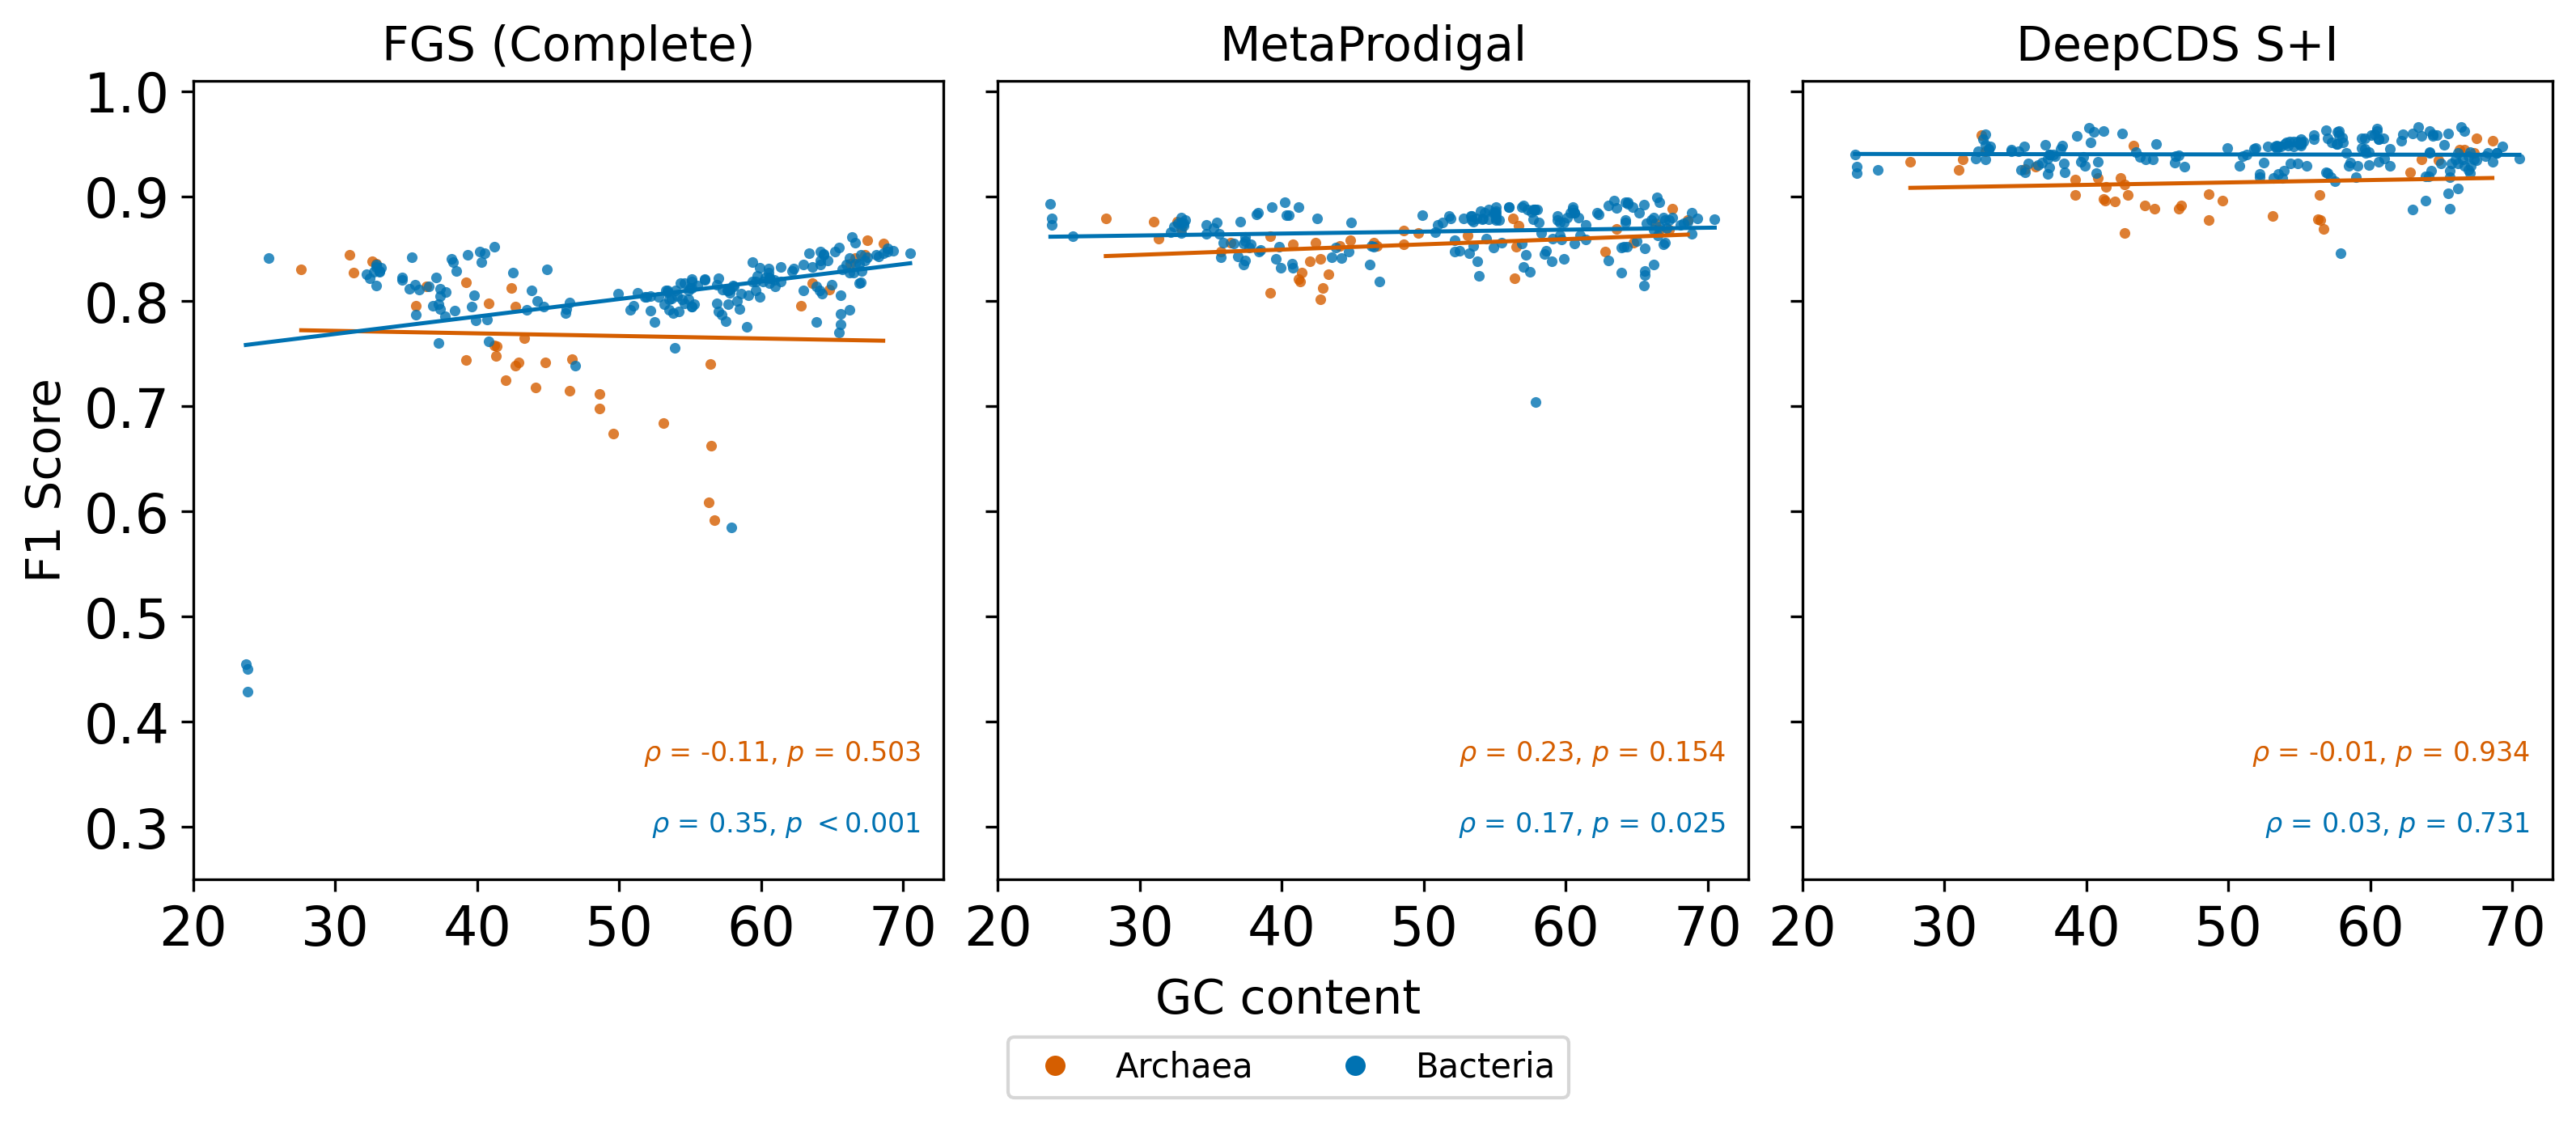

Spearman correlation: GC content vs. F1 Score
Model                      Domain          rho      p-value
------------------------------------------------------------------
FGS (Complete)             Archaea      -0.110       0.5032
FGS (Complete)             Bacteria      0.349    2.022e-06
MetaProdigal               Archaea       0.233       0.1542
MetaProdigal               Bacteria      0.169       0.0248
DeepCDS S+I                Archaea      -0.014       0.9344
DeepCDS S+I                Bacteria      0.026       0.7309


In [24]:
def plot_gc_vs_metric_scatter_subset(performance_metrics_dict, genome_metadata, metric_name, data_type,
                               model_order=None, model_display_names=None, colors=None,
                               max_cols=4):
    """
    Scatterplot of GC-content vs. per-genome performance metric, one panel per model.
    Reports Spearman correlation in each panel.

    Args:
        performance_metrics_dict (dict): {accession: {model: {metric: value, ...}}}
        genome_metadata (dict): {accession: {gc_content: float, domain: str, ...}}
        metric_name (str): metric key, e.g. 'f1_score'
        data_type (str): label for the figure title / save filename
        model_order (list, optional): order of models to plot
        model_display_names (dict, optional): {model_key: display_name}
        colors (list, optional): list of bar colors per model
        max_cols (int): maximum number of panels per row (default 4)
    """
    if model_order is None:
        model_order = list(next(iter(performance_metrics_dict.values())).keys())
    if model_display_names is None:
        model_display_names = {m: m for m in model_order}
    if colors is None:
        colors = ['#D55E00', '#009E73', '#CC79A7', '#0072B2']

    #Get subset of models for plot
    model_order = ['fgs_complete', 'prodigal', 'deep_cds_errors']
    # Build aligned arrays
    accessions = [acc for acc in performance_metrics_dict
                  if acc in genome_metadata and genome_metadata[acc].get('gc_content') is not None]

    gc_arr  = np.array([genome_metadata[acc]['gc_content'] for acc in accessions])
    domains = np.array([genome_metadata[acc].get('domain', 'Unknown') for acc in accessions])

    domain_colors = {'Bacteria': '#0072B2', 'Archaea': '#D55E00'}
    domain_labels = sorted(set(domains))

    n_models = len(model_order)
    n_cols = min(n_models, max_cols)
    n_rows = math.ceil(n_models / n_cols)

    matplotlib.rcParams['text.usetex'] = False
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(n_cols * 3.5, n_rows * 4.2),
                             sharey=True, constrained_layout=True)
    axes_flat = np.array(axes).flatten()

    for idx, (model, color) in enumerate(zip(model_order, colors)):
        ax = axes_flat[idx]
        f1_arr = np.array([
            performance_metrics_dict[acc][model].get(metric_name, np.nan)
            for acc in accessions
        ])
        valid = ~np.isnan(f1_arr)
        gc_v, f1_v, dom_v = gc_arr[valid], f1_arr[valid], domains[valid]

        # Points coloured by domain
        for domain in domain_labels:
            mask = dom_v == domain
            ax.scatter(gc_v[mask], f1_v[mask],
                       c=domain_colors.get(domain, 'grey'),
                       s=10, alpha=0.8, linewidths=0, label=domain)

        # Linear regression line per domain
        for domain in domain_labels:
            mask = dom_v == domain
            if mask.sum() < 2:
                continue
            gc_d, f1_d = gc_v[mask], f1_v[mask]
            m_reg, b_reg = np.polyfit(gc_d, f1_d, 1)
            x_line = np.linspace(gc_d.min(), gc_d.max(), 200)
            ax.plot(x_line, m_reg * x_line + b_reg,
                    color=domain_colors.get(domain, 'grey'), lw=1.2, zorder=5)

        # Spearman correlation per domain — bottom right corner
        annotation_lines = []
        for domain in domain_labels:
            mask = dom_v == domain
            if mask.sum() >= 3:
                rho_d, p_d = spearmanr(gc_v[mask], f1_v[mask])
                p_txt = r'$<$0.001' if p_d < 0.001 else f'= {p_d:.3f}'
                annotation_lines.append((rf'$\rho$ = {rho_d:.2f}, $p$ {p_txt}', domain_colors.get(domain, 'grey')))

        for line_idx, (text, col) in enumerate(reversed(annotation_lines)):
            ax.annotate(
                text,
                xy=(0.97, 0.05 + line_idx * 0.09), xycoords='axes fraction',
                fontsize=8, va='bottom', ha='right', color=col
            )

        ax.set_title(model_display_names.get(model, model), fontsize=14)
        ax.set_xticks(range(20, 75, 10))
        ax.set_ylim(0.25, 1.01)
        ax.set_yticks(np.arange(0.3, 1.01, 0.1))
        ax.tick_params(axis='x')

    # Hide any unused axes
    for idx in range(n_models, len(axes_flat)):
        axes_flat[idx].set_visible(False)

    # Y-axis label on leftmost column
    for row in range(n_rows):
        axes_flat[row * n_cols].set_ylabel(metric_name.replace('_', ' ').title(), fontsize=14)

    fig.supxlabel('GC content', fontsize=14)

    # Shared domain legend — centred at the bottom
    legend_handles = [
        Line2D([0], [0], marker='o', color='w',
               markerfacecolor=domain_colors.get(d, 'grey'),
               markersize=7, label=d)
        for d in domain_labels
    ]
    fig.legend(handles=legend_handles,
               loc='lower center', bbox_to_anchor=(0.5, -0.08),
               ncol=len(domain_labels)+1,
               fontsize=10, title_fontsize=10, frameon=True)

    # plt.savefig(f'gc_vs_{metric_name}_scatter_{data_type}.png', dpi=500, bbox_inches='tight')
    # plt.savefig(f'gc_vs_{metric_name}_scatter_{data_type}.svg', dpi=500, bbox_inches='tight')
    plt.show()

# Print correlation table
    print(f'Spearman correlation: GC content vs. {metric_name.replace("_", " ").title()}')
    print('=' * 66)
    print(f'{"Model":<26} {"Domain":<12} {"rho":>6} {"p-value":>12}')
    print('-' * 66)
    for model in model_order:
        f1_arr = np.array([
            performance_metrics_dict[acc][model].get(metric_name, np.nan)
            for acc in accessions
        ])
        valid = ~np.isnan(f1_arr)
        gc_v_all, f1_v_all, dom_v_all = gc_arr[valid], f1_arr[valid], domains[valid]
        for domain in domain_labels:
            mask = dom_v_all == domain
            if mask.sum() < 3:
                continue
            rho, p_rho = spearmanr(gc_v_all[mask], f1_v_all[mask])
            p_str = f'{p_rho:.3e}' if p_rho < 0.001 else f'{p_rho:.4f}'
            print(f'{model_display_names.get(model, model):<26} {domain:<12} {rho:>6.3f} {p_str:>12}')


for data_type in data_types:
    plot_gc_vs_metric_scatter_subset(
        all_performance_metrics_ordered, all_genomes, 'f1_score', data_type,
        model_order=model_order,
        model_display_names=model_display_names_ordered,
        colors=custom_colors,
    )

# Plot performance per Family

FileNotFoundError: [Errno 2] No such file or directory: '/tmp/nrt204/FragmentPredictor/illustrations/results/f1_score_per_family_with_errors_5e-06i_0.004s_300bp.png'

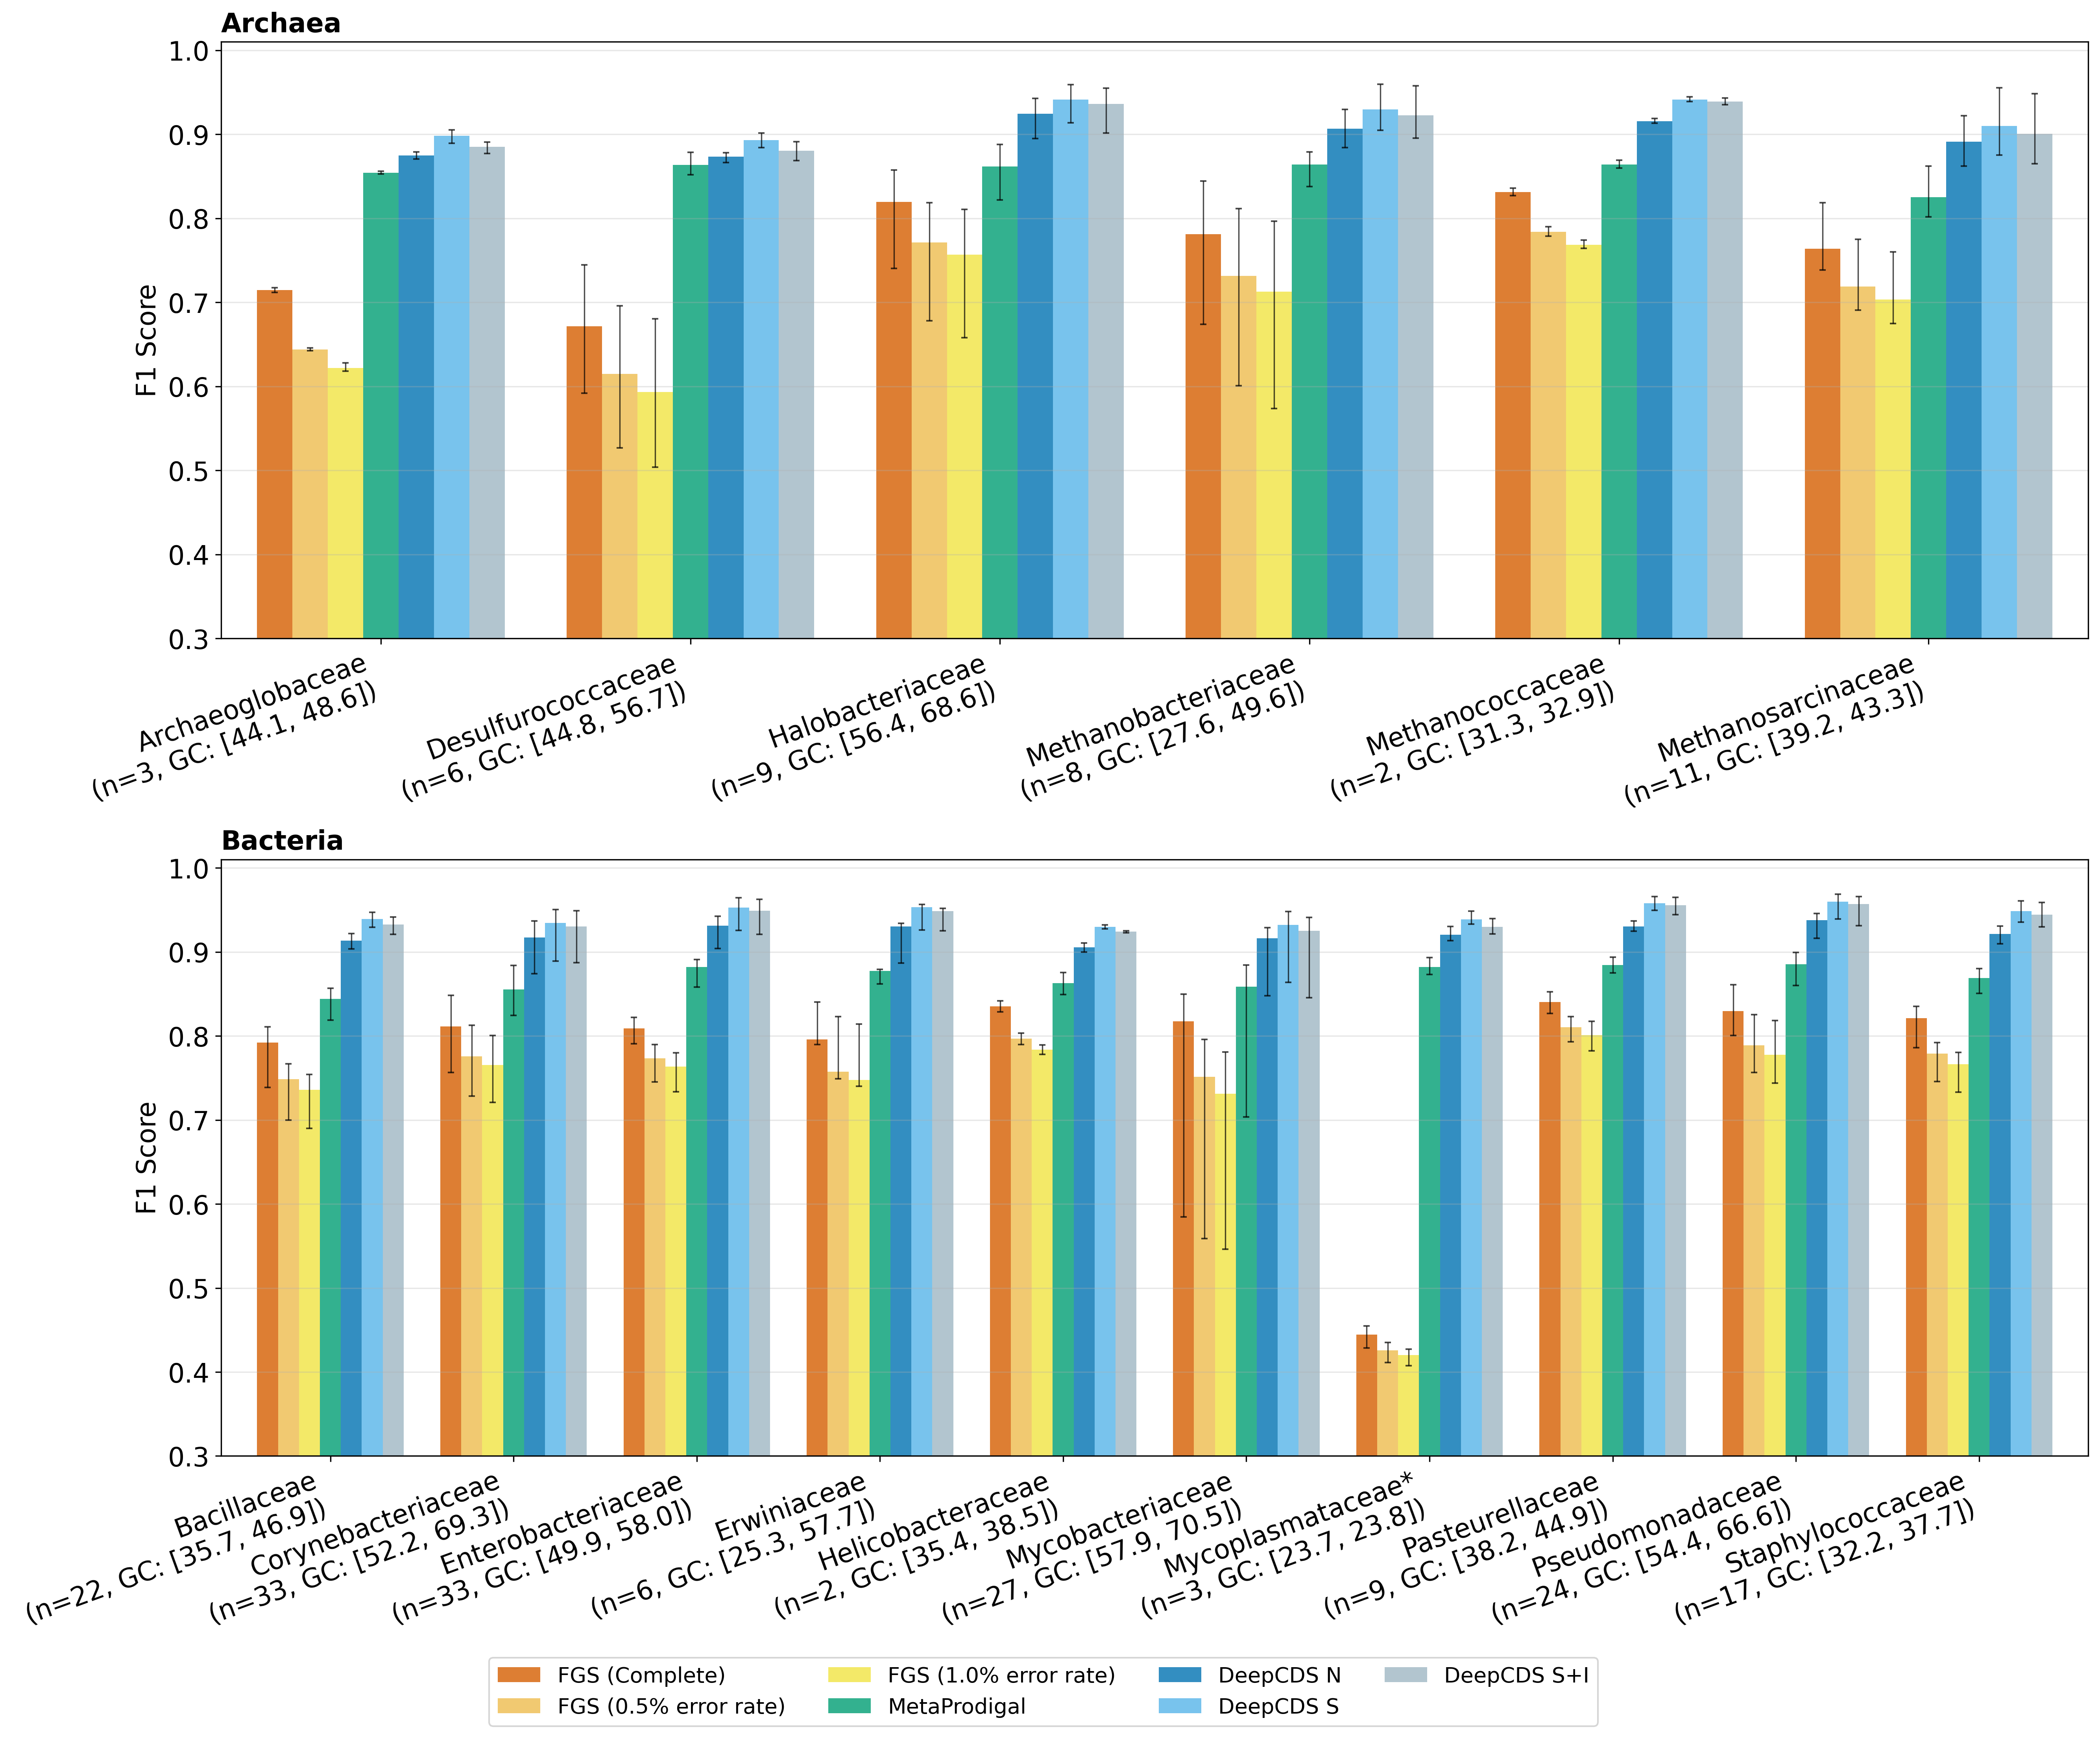

In [25]:
# Plot performance per family (aggregated across all genomes in each family)
for data_type in data_types:
    plot_metric_per_family_bars(all_performance_metrics_ordered, all_genomes, 'f1_score', data_type,
                                model_display_names=model_display_names_ordered, colors=custom_colors)

In [ ]:
# Generate LaTeX table for per-family performance (F1, Sensitivity, Precision)
def generate_family_latex_table(performance_metrics_dict, genome_metadata, model_order, model_display_names):
    """Generate a LaTeX booktabs table with family rows and model columns, best per family bolded."""
    model_names = model_order
    
    # Get all unique families and aggregate counts
    families = set()
    for acc in performance_metrics_dict.keys():
        if acc in genome_metadata:
            families.add(genome_metadata[acc]['family'])
    
    aggregated_counts = {family: {model: {'tp': 0, 'fp': 0, 'fn': 0, 'count': 0}
                                   for model in model_names}
                         for family in families}
    
    for acc, metrics in performance_metrics_dict.items():
        if acc not in genome_metadata:
            continue
        family = genome_metadata[acc]['family']
        for model in model_names:
            if model in metrics:
                aggregated_counts[family][model]['tp'] += metrics[model].get('total_true_positives', 0)
                aggregated_counts[family][model]['fp'] += metrics[model].get('total_false_positives', 0)
                aggregated_counts[family][model]['fn'] += metrics[model].get('total_false_negatives', 0)
                aggregated_counts[family][model]['count'] += 1
    
    # Compute metrics per family per model
    family_metrics = {}
    for family in families:
        family_metrics[family] = {}
        for model in model_names:
            c = aggregated_counts[family][model]
            tp, fp, fn = c['tp'], c['fp'], c['fn']
            precision = tp / (tp + fp) if (tp + fp) > 0 else 0
            recall = tp / (tp + fn) if (tp + fn) > 0 else 0
            f1 = 2 * precision * recall / (precision + recall) if (precision + recall) > 0 else 0
            family_metrics[family][model] = {'f1_score': f1, 'recall': recall, 'precision': precision}
    
    # Sort families alphabetically
    sorted_families = sorted(families)
    
    # Get genome counts per family
    genome_counts = {f: aggregated_counts[f][model_names[0]]['count'] for f in sorted_families}
    
    # Build LaTeX
    col_headers = [model_display_names.get(m, m) for m in model_names]
    n_cols = len(model_names)
    
    latex = []
    latex.append(r"\begin{table}[ht]")
    latex.append(r"\centering")
    latex.append(r"\begin{tabular}{l" + "c" * n_cols + "}")
    latex.append(r"\toprule")
    latex.append("Family (n) & " + " & ".join(col_headers) + r" \\")
    
    for metric_key, metric_label in [('f1_score', 'F1 Score')]:
        latex.append(r"\midrule")
        latex.append(r"\multicolumn{" + str(n_cols + 1) + r"}{l}{\textit{" + metric_label + r"}} \\")
        
        for family in sorted_families:
            values = [family_metrics[family][m][metric_key] for m in model_names]
            max_val = max(values)
            
            cells = []
            for v in values:
                formatted = f"{v:.3f}"
                if v == max_val:
                    cells.append(r"\textbf{" + formatted + "}")
                else:
                    cells.append(formatted)
            
            family_label = family + f" ({genome_counts[family]})"
            latex.append(family_label + " & " + " & ".join(cells) + r" \\")
    
    latex.append(r"\bottomrule")
    latex.append(r"\end{tabular}")
    latex.append(r"\caption{Aggregated CDS-level performance per family}")
    latex.append(r"\label{tab:family_performance}")
    latex.append(r"\end{table}")
    
    return "\n".join(latex)

for data_type in data_types:
    table = generate_family_latex_table(all_performance_metrics_ordered, all_genomes, model_order, model_display_names_ordered)
    print(table)

\begin{table}[ht]
\centering
\begin{tabular}{lccccccc}
\toprule
Family (n) & FGS (Complete) & FGS (0.5% error rate) & FGS (1.0% error rate) & MetaProdigal & DeepCDS N & DeepCDS S & DeepCDS S+I \\
\midrule
\multicolumn{8}{l}{\textit{F1 Score}} \\
Archaeoglobaceae (3) & 0.715 & 0.644 & 0.622 & 0.854 & 0.875 & \textbf{0.898} & 0.885 \\
Bacillaceae (22) & 0.792 & 0.749 & 0.736 & 0.844 & 0.913 & \textbf{0.939} & 0.933 \\
Corynebacteriaceae (33) & 0.811 & 0.776 & 0.765 & 0.855 & 0.917 & \textbf{0.935} & 0.930 \\
Desulfurococcaceae (6) & 0.671 & 0.615 & 0.594 & 0.864 & 0.873 & \textbf{0.893} & 0.880 \\
Enterobacteriaceae (33) & 0.809 & 0.773 & 0.764 & 0.882 & 0.931 & \textbf{0.953} & 0.949 \\
Erwiniaceae (6) & 0.796 & 0.758 & 0.748 & 0.878 & 0.930 & \textbf{0.953} & 0.949 \\
Halobacteriaceae (9) & 0.820 & 0.771 & 0.757 & 0.862 & 0.924 & \textbf{0.941} & 0.936 \\
Helicobacteraceae (2) & 0.835 & 0.797 & 0.784 & 0.863 & 0.905 & \textbf{0.930} & 0.924 \\
Methanobacteriaceae (8) & 0.781 & 0.732 & 

# Plot performance by GC-content separated by Translation Table

In [ ]:
# Filter performance metrics by translation table
tt4_performance_metrics = {acc: metrics for acc, metrics in all_performance_metrics_dict.items() 
                           if acc in all_genomes and all_genomes[acc]['translation_table'] == 4}
tt11_performance_metrics = {acc: metrics for acc, metrics in all_performance_metrics_dict.items() 
                            if acc in all_genomes and all_genomes[acc]['translation_table'] == 11}

print(f"TT4 genomes with metrics: {len(tt4_performance_metrics)}")
print(f"TT11 genomes with metrics: {len(tt11_performance_metrics)}")

TT4 genomes with metrics: 3
TT11 genomes with metrics: 212


TRANSLATION TABLE 11 (Standard Bacterial/Archaeal Code)


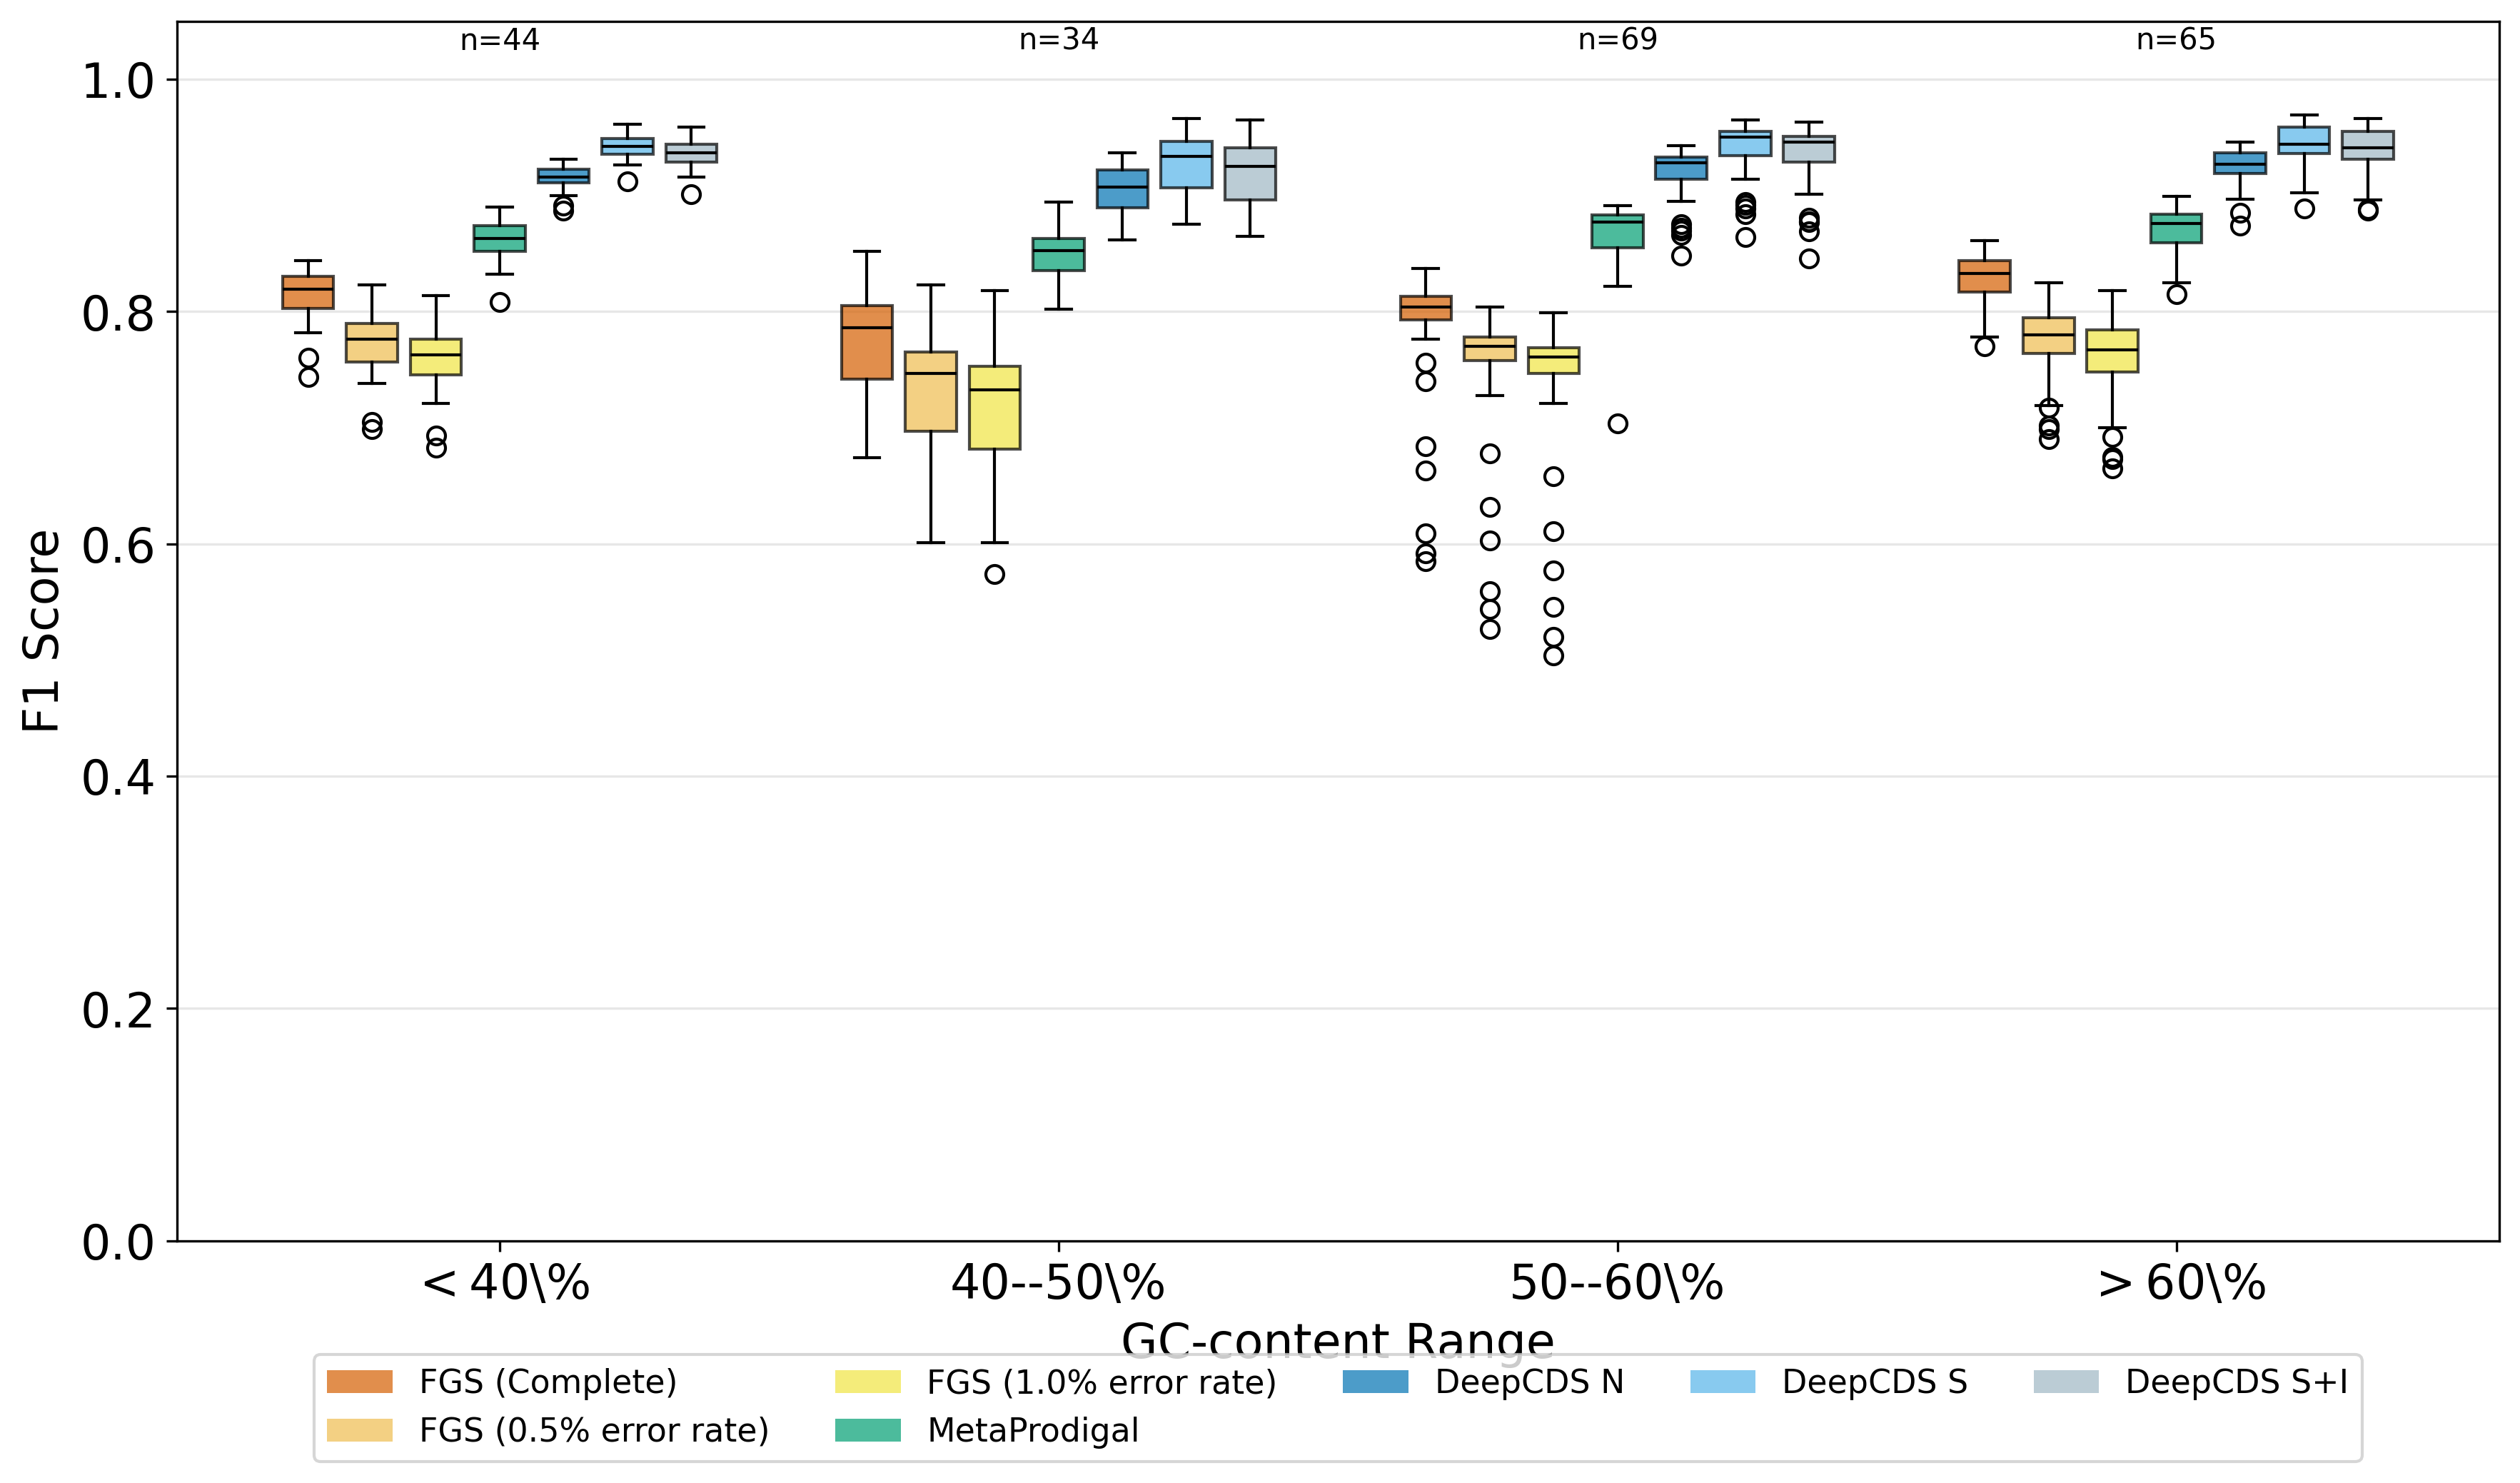

In [ ]:
# Plot for Translation Table 11 only (standard bacterial/archaeal code)
tt11_performance_metrics_ordered = reorder_metrics(tt11_performance_metrics, model_order)

for data_type in data_types:
    print("=" * 60)
    print("TRANSLATION TABLE 11 (Standard Bacterial/Archaeal Code)")
    print("=" * 60)
    
    # Boxplots
    plot_metric_by_gc_content_boxplot(tt11_performance_metrics_ordered, all_genomes, 'f1_score', 
                                      f"{data_type} - Translation Table 11",
                                      model_display_names=model_display_names_ordered, colors=custom_colors)
    